## scGPT benchmarking

In this notebook we test our best scGPT pipeline with several different cases/patients and several different cells to understand how performance varies across all of these.

### 1. Kidney 

In [1]:
# 1 — Paths and settings: edit this cell only to choose specimens/run size.
from pathlib import Path
from datetime import datetime, timezone
import gc
import gzip
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import sys
import time

import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread
from threadpoolctl import threadpool_limits
import torch
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
LAB_ROOT = Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale")
META = LAB_ROOT / "metadata/sample_md.tsv"
GDC_ROOT = LAB_ROOT / "GDC-data"
MODEL = ROOT / "models/whole-human"
HELPER = ROOT / "notebooks/scgpt_session/scgpt_session.py"
HISTORICAL = ROOT / "sanity_check/reference_4068d67/scgpt"
CENSUS_ANNOTATION = ROOT / "sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"

# Same diagnosis initially; distinct patients. Edit/add IDs after inspecting metadata.
SAMPLE_IDS = ["C3N-00148-01", "C3L-00359-01", "C3L-01287-01"]
# For example, add "C3L-03405-01" later for a brain/glioblastoma specimen.

# If automatic discovery finds multiple matrices, explicitly set a directory here.
MATRIX_DIR_OVERRIDES = {}       # {"sample-id": Path("/absolute/path/to/mex_directory")}
COPYKAT_OVERRIDES = {}         # Optional: {"sample-id": Path("/absolute/path/to/prediction.txt")}

MODE = "full"                # Change to "full" after checking the pilot.
assert MODE in {"pilot", "full"}
SPLIT_SEED = 42
N_REFERENCE = 128
N_EVALUATION = 128
MASK_FRACTION = 0.25
MASK_SEEDS = [42] if MODE == "pilot" else [42, 43, 44, 45]
MAX_EVALUATED = 8 if MODE == "pilot" else N_EVALUATION
ACTIVE_SAMPLE_IDS = SAMPLE_IDS[:1] if MODE == "pilot" else SAMPLE_IDS
RUN_SHUFFLED = True
SAVE_QUERY_PREDICTIONS = True  # Compressed per-mask files; no dense expression export.
N_THREADS = 4
torch.set_num_threads(N_THREADS)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
RUN_DIR = ROOT / "multicase_expression/results" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

required = [META, HELPER, HISTORICAL / "preprocess.py",
            HISTORICAL / "data_collator.py", CENSUS_ANNOTATION]
required += [MODEL / f for f in ["args.json", "vocab.json", "best_model.pt"]]
for path in required:
    assert path.is_file(), f"Required existing file not found: {path}"
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| threads:", torch.get_num_threads())
print("Mode:", MODE, "| active specimens:", ACTIVE_SAMPLE_IDS)
print("Output:", RUN_DIR)


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
PyTorch: 2.2.2+cpu | threads: 4
Mode: full | active specimens: ['C3N-00148-01', 'C3L-00359-01', 'C3L-01287-01']
Output: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full


In [2]:
# 2 — Pin the preprocessing binding and load every checkpoint tensor strictly.
def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

session = import_file("multicase_verified_session", HELPER)
historical = import_file("multicase_historical_preprocess", HISTORICAL / "preprocess.py")
historical_collator = import_file(
    "scgpt._multicase_historical_collator", HISTORICAL / "data_collator.py"
)
historical_collator.binning = historical.binning
assert historical_collator.binning is historical.binning
assert historical._digitize.__defaults__ == ("one",), "Unexpected tie rule."

model, loaded_vocab, config = session.load_model(MODEL)
model = model.cpu().eval()
vocab = loaded_vocab.get_stoi()
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
pad_id = vocab[config.get("pad_token", "<pad>")]
cls_id = vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value,
    do_mlm=True, do_binning=True, mlm_probability=MASK_FRACTION,
    mask_value=config.get("mask_value", -1), max_length=config["max_seq_len"],
    sampling=True, keep_first_n_tokens=1, data_style="both",
)
print("Helper:", session.__file__)
print("Historical tie rule:", historical._digitize.__defaults__)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b""):
            digest.update(block)
    return digest.hexdigest()

run_manifest = {
    "run_id": RUN_ID, "mode": MODE, "sample_ids": ACTIVE_SAMPLE_IDS,
    "split_seed": SPLIT_SEED, "n_reference": N_REFERENCE,
    "n_evaluation_reserved": N_EVALUATION, "n_evaluated": MAX_EVALUATED,
    "mask_seeds": MASK_SEEDS, "mask_fraction": MASK_FRACTION,
    "run_shuffled": RUN_SHUFFLED, "config": config,
    "helper_path": str(HELPER), "helper_sha256": sha256(HELPER),
    "checkpoint_sha256": sha256(MODEL / "best_model.pt"),
    "vocab_sha256": sha256(MODEL / "vocab.json"),
    "historical_commit": "4068d67caaac1e28d56964da68e0214817e38428",
    "historical_preprocess_sha256": sha256(HISTORICAL / "preprocess.py"),
    "historical_collator_sha256": sha256(HISTORICAL / "data_collator.py"),
    "census_annotation_path": str(CENSUS_ANNOTATION),
    "versions": {p: importlib.metadata.version(p) for p in
                 ["torch", "scgpt", "anndata", "numpy", "scipy", "pandas"]},
    "python": sys.version, "platform": platform.platform(),
    "baseline_scope": "Separate reference cells within each specimen; positive-gene bin means",
    "qc_policy": "No new biological QC exclusions; require enough detected model genes for >=1 query",
    "limitations": [
        "Current specimen has already been explored; new patients are replication data",
        "Only detected genes are queried; zero measurements are not evaluated",
        "Full-profile quantile boundaries use hidden expression values",
        "CopyKAT categories are predictions, not cell-type or malignancy truth",
        "Masks and queried genes within a patient are not independent patients",
        "Pinned preprocessing is verified; exact released checkpoint training commit is unconfirmed",
    ],
}
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Strict load: 163 checkpoint tensors; no omitted tensors.
Helper: /home/akash1/scgpt-cna/notebooks/scgpt_session/scgpt_session.py
Historical tie rule: ('one',)


3573

In [3]:
# 3 — Inspect sample identities and discover sparse 10x files, without loading counts.
metadata = pd.read_csv(META, sep="\t", dtype=str)
assert metadata["sample_id"].is_unique
missing = set(SAMPLE_IDS) - set(metadata["sample_id"])
assert not missing, f"IDs absent from sample metadata: {sorted(missing)}"
selected_metadata = metadata.set_index("sample_id").loc[SAMPLE_IDS].reset_index()
assert selected_metadata["case_id"].is_unique, "Choose one specimen per patient initially."

def sidecar(directory, stem):
    candidates = [directory / stem, directory / (stem + ".gz")]
    found = [p for p in candidates if p.is_file()]
    assert len(found) == 1, f"Expected one {stem}(.gz) in {directory}; found {found}"
    return found[0]

def discover_sample(record):
    sid, case = record["sample_id"], record["case_id"]
    sample_dir = GDC_ROOT / case / sid
    assert sample_dir.is_dir(), f"Missing sample directory: {sample_dir}"
    if sid in MATRIX_DIR_OVERRIDES:
        matrix_dir = Path(MATRIX_DIR_OVERRIDES[sid])
    else:
        # Search only this specimen's single_cell subtree; ignore dense CSVs/archives.
        candidates = sorted({p.parent for p in (sample_dir / "single_cell").rglob("matrix.mtx*")
                             if p.name in {"matrix.mtx", "matrix.mtx.gz"}})
        filtered = [p for p in candidates if "filtered" in str(p).lower()
                    and "raw_feature" not in str(p).lower()]
        if filtered:
            candidates = filtered
        assert len(candidates) == 1, (
            f"Ambiguous/missing MEX directory for {sid}: {candidates}. "
            "Set MATRIX_DIR_OVERRIDES explicitly. Do not choose a raw droplet matrix."
        )
        matrix_dir = candidates[0]
    ck = ([Path(COPYKAT_OVERRIDES[sid])] if sid in COPYKAT_OVERRIDES else
          sorted((sample_dir / "single_cell").rglob("*copykat_prediction.txt")))
    assert len(ck) <= 1, f"Multiple CopyKAT files for {sid}; set COPYKAT_OVERRIDES."
    if ck:
        assert ck[0].is_file()
    return {
        **record, "sample_directory": str(sample_dir),
        "matrix_file": str(sidecar(matrix_dir, "matrix.mtx")),
        "features_file": str(sidecar(matrix_dir, "features.tsv")),
        "barcodes_file": str(sidecar(matrix_dir, "barcodes.tsv")),
        "copykat_file": str(ck[0]) if ck else "",
    }

manifest = pd.DataFrame([discover_sample(r) for r in selected_metadata.to_dict("records")])
display(manifest[["case_id", "sample_id", "primary_site",
                  "diagnoses.0.primary_diagnosis", "wgd_status", "matrix_file"]])
manifest.to_csv(RUN_DIR / "sample_manifest.tsv", sep="\t", index=False)
print("All selected specimens have an unambiguous sparse matrix.")


,case_id,sample_id,primary_site,diagnoses.0.primary_diagnosis,wgd_status,matrix_file
0,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
1,C3L-00359,C3L-00359-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
2,C3L-01287,C3L-01287-01,Kidney,"Renal cell carcinoma, NOS",WGD-,/home/akash1/projects/rrg-tperkins/dgladish/Pr...


All selected specimens have an unambiguous sparse matrix.


In [4]:
# 4 — Load the shared annotation map; define sparse loading and harmonization.
# Census counts are never read here. Feature IDs connect alternative gene symbols.
census_annotation = ad.read_h5ad(CENSUS_ANNOTATION, backed="r")
census_var = census_annotation.var[["feature_id", "feature_name"]].copy()
census_annotation.file.close()
del census_annotation

def base_ids(values):
    # Strip only terminal Ensembl version numbers. Keep PAR_Y identities separate.
    return pd.Series(values, dtype="string").str.replace(r"\.\d+$", "", regex=True)

census_var["ensembl_base"] = base_ids(census_var["feature_id"].to_numpy()).to_numpy()
symbol_counts = census_var.groupby("ensembl_base")["feature_name"].nunique()
unambiguous_ids = symbol_counts.index[symbol_counts.eq(1)]
id_to_symbol = (
    census_var.loc[census_var["ensembl_base"].isin(unambiguous_ids)]
    .drop_duplicates("ensembl_base").set_index("ensembl_base")["feature_name"]
)
print("Unambiguous annotation IDs:", len(id_to_symbol))
print("Ambiguous IDs excluded:", int(symbol_counts.gt(1).sum()))

def load_lab_sample(record):
    started = time.perf_counter()
    features = pd.read_csv(record["features_file"], sep="\t", header=None, dtype=str)
    barcodes = pd.read_csv(record["barcodes_file"], sep="\t", header=None, dtype=str)[0]
    assert features.shape[1] >= 3 and barcodes.is_unique
    with threadpool_limits(limits=N_THREADS):
        matrix_path = Path(record["matrix_file"])
        if matrix_path.suffix == ".gz":
            with gzip.open(matrix_path, "rb") as stream:
                raw = mmread(stream).T.tocsr()
        else:
            raw = mmread(matrix_path).T.tocsr()
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == (len(barcodes), len(features))
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected integer UMI counts."
    gex = features[2].eq("Gene Expression").to_numpy()
    assert gex.any()
    raw = raw[:, gex].tocsr()
    var = features.loc[gex, [0, 1, 2]].reset_index(drop=True)
    var.columns = ["gene_id", "gene_symbol", "feature_type"]
    assert var["gene_id"].is_unique, "Duplicate feature IDs require an explicit resolution."
    var["ensembl_base"] = base_ids(var["gene_id"]).to_numpy()
    var["census_symbol"] = var["ensembl_base"].map(id_to_symbol)
    # Prefer a recognized ID-matched Census symbol; otherwise retain a recognized lab symbol.
    mapped_ok = var["census_symbol"].isin(vocab)
    var["model_symbol"] = var["census_symbol"].where(mapped_ok, var["gene_symbol"])
    original_keep = var["gene_symbol"].isin(vocab) & ~var["gene_symbol"].duplicated()
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    columns = np.flatnonzero(keep.to_numpy())
    gene_info = var.iloc[columns].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, columns].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = pd.DataFrame(index=pd.Index(barcodes.to_numpy(), name="barcode"))
    obs["cell_index"] = np.arange(len(obs))
    obs["case_id"], obs["sample_id"] = record["case_id"], record["sample_id"]
    obs["cell_id"] = record["sample_id"] + ":" + obs.index.astype(str)
    obs["tissue"] = record["primary_site"]
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["sample_wgd_status"] = record["wgd_status"]
    obs["cell_type"] = "unassigned"
    obs["malignant_status"] = "unresolved"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mt_columns = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = (100 * np.asarray(raw[:, mt_columns].sum(axis=1)).ravel()
                            / obs["total_counts"].replace(0, np.nan))
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = (np.asarray(ones.sum(axis=1)).ravel()
                                  / obs["detected_genes"].replace(0, np.nan))
    del ones

    # Full-profile, deterministic model-bin summaries for each cell.
    model_singletons, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i + 1]]
        if not len(counts):
            model_singletons.append(np.nan); occupied.append(0)
            dominant.append(np.nan); singleton_bin.append(np.nan)
            continue
        labels = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(labels, return_counts=True)
        one = counts == 1
        model_singletons.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(labels)))
        singleton_bin.append(float(labels[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = model_singletons
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin

    obs["copykat_group"] = "missing_from_output"
    unmatched_copykat_barcodes = 0
    if record["copykat_file"]:
        ck = pd.read_csv(record["copykat_file"], sep="\t", dtype=str)
        assert {"cell.names", "copykat.pred"}.issubset(ck.columns)
        assert ck["cell.names"].is_unique
        unmatched_copykat_barcodes = int((~ck["cell.names"].isin(obs.index)).sum())
        obs["copykat_group"] = (ck.set_index("cell.names")["copykat.pred"]
                                 .reindex(obs.index).fillna("missing_from_output"))
    # Clusters, when already downloaded, are retained as cluster IDs, not cell types.
    obs["seurat_cluster"] = "not_available"
    seurat_path = ROOT / "measurement_analysis" / record["sample_id"] / "gdc_secondary_analysis/seurat.analysis.tsv"
    if seurat_path.is_file():
        seurat = pd.read_csv(seurat_path, sep="\t", dtype=str)
        assert {"cell_barcode", "seurat_cluster"}.issubset(seurat.columns)
        assert seurat["cell_barcode"].is_unique
        obs["seurat_cluster"] = (seurat.set_index("cell_barcode")["seurat_cluster"]
                                   .reindex(obs.index).fillna("not_available"))

    total = float(raw.sum())
    report = {
        "sample_id": record["sample_id"], "case_id": record["case_id"],
        "tissue": record["primary_site"], "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(raw[:, original_keep.to_numpy()].sum()) / total,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": unmatched_copykat_barcodes,
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    del raw
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


Unambiguous annotation IDs: 60664
Ambiguous IDs excluded: 0


In [5]:
# 5 — Independent reference cells, native-bin baselines and verified model inputs.
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]

def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])

def reserve_cells(obs):
    minimum_genes = max(2, int(np.ceil(1 / MASK_FRACTION)))
    eligible = np.flatnonzero(obs["model_detected_genes"].to_numpy() >= minimum_genes)
    assert len(eligible) >= N_REFERENCE + N_EVALUATION, (
        f"Only {len(eligible)} eligible cells; need {N_REFERENCE + N_EVALUATION}. "
        "If reducing the budget, use the same setting for all specimens."
    )
    order = np.random.default_rng(SPLIT_SEED).permutation(eligible)
    reference = order[:N_REFERENCE]
    evaluation = order[N_REFERENCE:N_REFERENCE + N_EVALUATION]
    assert not set(reference) & set(evaluation)
    return reference, evaluation

def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

def make_example(matrix, gene_ids, i):
    row = matrix.getrow(int(i))
    return {
        "genes": torch.tensor(np.concatenate(([cls_id], gene_ids[row.indices])), dtype=torch.long),
        "expressions": torch.tensor(np.concatenate(([pad_value], row.data)), dtype=torch.float32),
    }

def make_batch(matrix, gene_ids, evaluation, seed):
    # Always collate ALL reserved cells, even for an eight-cell pilot. The collator
    # chooses lengths using the batch. Fresh examples avoid in-place double binning.
    old_np = np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            np.random.seed(seed)
            return collator([make_example(matrix, gene_ids, i) for i in evaluation])
    finally:
        np.random.set_state(old_np)

def verified_input(matrix, gene_ids, batch, j, i):
    vm = batch["pcpt_gene"][j].ne(pad_id)
    qm = batch["gen_gene"][j].ne(pad_id)
    known_ids = batch["pcpt_gene"][j, vm]
    known_values = batch["pcpt_expr"][j, vm]
    query_ids = batch["gen_gene"][j, qm]
    target = batch["gen_expr_target"][j, qm].cpu().numpy().astype(float)
    assert int(known_ids[0]) == cls_id and float(known_values[0]) == pad_value
    assert len(query_ids) and len(known_ids) > 1
    assert cls_id not in query_ids.tolist()
    assert len(known_ids) + len(query_ids) <= config["max_seq_len"]
    row = matrix.getrow(int(i))
    tokens = gene_ids[row.indices]
    positions = {int(t): k for k, t in enumerate(tokens)}
    vi = np.array([positions[t] for t in known_ids[1:].tolist()], dtype=int)
    qi = np.array([positions[t] for t in query_ids.tolist()], dtype=int)
    assert len(set(vi)) == len(vi) and len(set(qi)) == len(qi)
    assert not np.intersect1d(vi, qi).size
    native = np.asarray(historical.binning(row.data.copy(), n_bins=51))
    np.testing.assert_array_equal(native[vi], known_values[1:].cpu().numpy())
    np.testing.assert_array_equal(native[qi], target)
    # Independent quantile/search check, in addition to the historical implementation.
    edges = np.quantile(row.data, np.linspace(0, 1, 50))
    np.testing.assert_array_equal(native, np.searchsorted(edges, row.data, side="right"))
    return known_ids, known_values, query_ids, target, row, vi, qi

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = model(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def summarize_scores(scores):
    # Average masks WITHIN each cell first. A cell has one weight in each group.
    keys = ["sample_id", "case_id", "cell_id", "cell_index", "method", "count_group"]
    per_cell = scores.groupby(keys, as_index=False).agg(
        MSE=("MSE", "mean"), MAE=("MAE", "mean"),
        mean_residual=("mean_residual", "mean"), target_std=("target_std", "mean"),
        prediction_std=("prediction_std", "mean"),
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
    )
    baseline = per_cell.loc[per_cell["method"].eq("gene_mean_plus_offset"),
                           ["cell_id", "count_group", "MSE"]].rename(columns={"MSE": "baseline_MSE"})
    per_cell = per_cell.merge(baseline, on=["cell_id", "count_group"], validate="many_to_one")
    per_cell["MSE_gain"] = per_cell["baseline_MSE"] - per_cell["MSE"]
    summary = per_cell.groupby(["sample_id", "case_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"),
        median_MSE=("MSE", "median"), mean_MAE=("MAE", "mean"),
        mean_MSE_gain=("MSE_gain", "mean"), cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
    )
    # This is a ratio of mean losses, not an average of per-cell percentages.
    summary["mean_baseline_MSE"] = summary["mean_MSE"] + summary["mean_MSE_gain"]
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    return per_cell, summary


In [6]:
# 6 — Run the pilot/full benchmark. Sparse matrices are processed one specimen at a time.
def run_sample(record):
    sid = record["sample_id"]
    destination = RUN_DIR / sid
    destination.mkdir(exist_ok=True)
    started = time.perf_counter()
    print(f"\nLoading {sid}: {record['primary_site']} | {record['diagnoses.0.primary_diagnosis']}", flush=True)
    matrix, gene_ids, gene_info, obs, report = load_lab_sample(record)
    reference, reserved_evaluation = reserve_cells(obs)
    evaluation = reserved_evaluation[:MAX_EVALUATED]
    means, support, constant = fit_baseline(matrix, reference)

    obs["split"] = "unused"
    obs.iloc[reference, obs.columns.get_loc("split")] = "reference"
    obs.iloc[reserved_evaluation, obs.columns.get_loc("split")] = "evaluation_reserved"
    obs["evaluated_this_run"] = obs["cell_index"].isin(evaluation)
    obs.to_csv(destination / "cell_metadata_and_splits.tsv", sep="\t")
    gene_info.assign(gene_token=gene_ids, reference_support=support, reference_mean=means).to_csv(
        destination / "gene_mapping_and_baseline.tsv.gz", sep="\t", index=False)
    report.update({"reference_constant": constant, "n_reference": len(reference),
                   "n_evaluated": len(evaluation), "n_reserved_evaluation": len(reserved_evaluation)})
    print(f"Cells {len(obs):,}; model features {matrix.shape[1]:,}; "
          f"counts retained {report['harmonized_percent_counts']:.4f}%", flush=True)
    print(f"Reference {len(reference)}; reserved evaluation {len(reserved_evaluation)}; "
          f"running {len(evaluation)}; reference constant {constant:.3f}", flush=True)
    display(obs.iloc[evaluation[:8]][["case_id", "sample_id", "copykat_group", "total_counts",
                                      "detected_genes", "model_count_fraction", "pct_counts_mt"]])
    score_rows = []
    for seed in MASK_SEEDS:
        batch = make_batch(matrix, gene_ids, reserved_evaluation, seed)
        query_frames = []
        for j, i in enumerate(evaluation):
            ki, kv, qi_tokens, target, row, vi, qi = verified_input(
                matrix, gene_ids, batch, j, int(i))
            query_mean = means[row.indices[qi]]
            # All target-specimen adaptation uses VISIBLE labels only.
            offset = float((kv[1:].cpu().numpy() - means[row.indices[vi]]).mean())
            predictions = {
                "gene_mean": query_mean,
                "gene_mean_plus_offset": query_mean + offset,
                "reference_constant": np.full(len(target), constant),
                "visible_mean": np.full(len(target), float(kv[1:].mean())),
                **predict(ki, kv, qi_tokens),
            }
            if RUN_SHUFFLED:
                shuffle_rng = np.random.default_rng(np.random.SeedSequence([2026, seed, int(i)]))
                shuffled_values = kv.clone()
                shuffled_values[1:] = torch.as_tensor(
                    shuffle_rng.permutation(kv[1:].cpu().numpy()), dtype=kv.dtype)
                predictions.update({head + "_shuffled": p for head, p in
                                    predict(ki, shuffled_values, qi_tokens).items()})
            identity = {"sample_id": sid, "case_id": record["case_id"],
                        "cell_id": obs.iloc[i]["cell_id"], "cell_index": int(i), "mask_seed": seed}
            score_rows.extend(score_predictions(
                predictions, target, row.data[qi], support[row.indices[qi]],
                {**identity, "n_visible_genes": len(vi), "n_query_genes": len(qi),
                 "visible_offset": offset, "copykat_group": obs.iloc[i]["copykat_group"]}))
            if SAVE_QUERY_PREDICTIONS:
                query_frames.append(pd.DataFrame({
                    **identity, "gene_token": qi_tokens.cpu().numpy(),
                    "original_umi": row.data[qi].astype(int), "target_bin": target,
                    "reference_support": support[row.indices[qi]], **predictions,
                }))
            if (j + 1) % 16 == 0 or j + 1 == len(evaluation):
                print(f"{sid} | mask {seed} | completed {j + 1}/{len(evaluation)}", flush=True)
        if query_frames:
            pd.concat(query_frames, ignore_index=True).to_csv(
                destination / f"query_predictions_mask{seed}.csv.gz", index=False)
        del batch, query_frames
        # Preserve completed masks if a later mask is interrupted.
        pd.DataFrame(score_rows).to_csv(destination / "scores_by_cell_mask_group.csv", index=False)

    scores = pd.DataFrame(score_rows)
    per_cell, summary = summarize_scores(scores)
    details = obs.reset_index()[["cell_id", "barcode", "copykat_group", "seurat_cluster",
                                "total_counts", "detected_genes", "model_detected_genes",
                                "fraction_count_one", "model_fraction_count_one", "pct_counts_mt",
                                "model_count_fraction", "occupied_bins", "dominant_bin_fraction"]]
    per_cell = per_cell.merge(details, on="cell_id", validate="many_to_one")
    per_cell.to_csv(destination / "scores_by_cell.csv", index=False)
    summary.to_csv(destination / "summary_by_count_group.csv", index=False)
    report["elapsed_seconds"] = time.perf_counter() - started
    (destination / "sample_audit.json").write_text(json.dumps(report, indent=2))
    print(f"Finished {sid}: {report['elapsed_seconds']:.1f} seconds", flush=True)
    display(summary.loc[summary["count_group"].eq("all")].round(3))
    del matrix
    gc.collect()
    return {"audit": report, "obs": obs, "per_cell": per_cell, "summary": summary}

results = []
for record in manifest.loc[manifest["sample_id"].isin(ACTIVE_SAMPLE_IDS)].to_dict("records"):
    results.append(run_sample(record))
print("\nSaved to:", RUN_DIR)



Loading C3N-00148-01: Kidney | Renal cell carcinoma, NOS
Cells 7,598; model features 60,566; counts retained 99.9848%
Reference 128; reserved evaluation 128; running 128; reference constant 38.665


,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
TCACGGGCATTCTTCA-1,C3N-00148,C3N-00148-01,aneuploid,4157,2052,0.999038,0.120279
AATCGACAGAGGCCAT-1,C3N-00148,C3N-00148-01,diploid,1205,897,1.000000,5.560166
TATCTTGGTACCATAC-1,C3N-00148,C3N-00148-01,diploid,3113,1630,0.999679,14.359139
ATCACGATCCATAGGT-1,C3N-00148,C3N-00148-01,diploid,3079,1601,1.000000,9.678467
GCGAGAACATACCGTA-1,C3N-00148,C3N-00148-01,aneuploid,2527,1399,0.999604,0.118718
GCACGGTGTAGATCGG-1,C3N-00148,C3N-00148-01,aneuploid,3571,1987,0.999440,0.140017
CGGGTGTTCTTGCAAG-1,C3N-00148,C3N-00148-01,diploid,7392,2887,1.000000,9.713203
CCTCTAGAGAATAACC-1,C3N-00148,C3N-00148-01,aneuploid,2000,1115,1.000000,0.150000


C3N-00148-01 | mask 42 | completed 16/128
C3N-00148-01 | mask 42 | completed 32/128
C3N-00148-01 | mask 42 | completed 48/128
C3N-00148-01 | mask 42 | completed 64/128
C3N-00148-01 | mask 42 | completed 80/128
C3N-00148-01 | mask 42 | completed 96/128
C3N-00148-01 | mask 42 | completed 112/128
C3N-00148-01 | mask 42 | completed 128/128
C3N-00148-01 | mask 43 | completed 16/128
C3N-00148-01 | mask 43 | completed 32/128
C3N-00148-01 | mask 43 | completed 48/128
C3N-00148-01 | mask 43 | completed 64/128
C3N-00148-01 | mask 43 | completed 80/128
C3N-00148-01 | mask 43 | completed 96/128
C3N-00148-01 | mask 43 | completed 112/128
C3N-00148-01 | mask 43 | completed 128/128
C3N-00148-01 | mask 44 | completed 16/128
C3N-00148-01 | mask 44 | completed 32/128
C3N-00148-01 | mask 44 | completed 48/128
C3N-00148-01 | mask 44 | completed 64/128
C3N-00148-01 | mask 44 | completed 80/128
C3N-00148-01 | mask 44 | completed 96/128
C3N-00148-01 | mask 44 | completed 112/128
C3N-00148-01 | mask 44 | comp

,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction
24,C3N-00148-01,C3N-00148,all,GEP,128,14.450,14.094,2.908,1.869,95,16.318,11.450
25,C3N-00148-01,C3N-00148,all,GEP_shuffled,128,15.330,14.896,3.282,0.989,81,16.318,6.059
26,C3N-00148-01,C3N-00148,all,MVC,128,14.577,14.297,2.872,1.742,94,16.318,10.673
27,C3N-00148-01,C3N-00148,all,MVC_shuffled,128,15.362,14.967,3.207,0.956,81,16.318,5.860
28,C3N-00148-01,C3N-00148,all,gene_mean,128,21.272,18.399,3.780,-4.954,8,16.318,-30.356
29,C3N-00148-01,C3N-00148,all,gene_mean_plus_offset,128,16.318,15.300,3.187,0.000,0,16.318,0.000
30,C3N-00148-01,C3N-00148,all,reference_constant,128,23.349,19.484,4.004,-7.030,1,16.318,-43.081
31,C3N-00148-01,C3N-00148,all,visible_mean,128,17.931,17.163,3.479,-1.612,32,16.318,-9.880



Loading C3L-00359-01: Kidney | Renal cell carcinoma, NOS
Cells 14,598; model features 60,566; counts retained 99.9942%
Reference 128; reserved evaluation 128; running 128; reference constant 37.245


,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
ACCTGAATCCAATGCA-1,C3L-00359,C3L-00359-01,not.defined,813,576,1.000000,2.952030
AGGGTTTAGTGAGTGC-1,C3L-00359,C3L-00359-01,aneuploid,3770,1718,1.000000,0.424403
CTGGCAGTCCAGTGTA-1,C3L-00359,C3L-00359-01,diploid,1530,1059,1.000000,1.241830
GTTGTCCTCCATTCAT-1,C3L-00359,C3L-00359-01,aneuploid,4769,2589,1.000000,0.083875
TTGGGATCAGAGCCCT-1,C3L-00359,C3L-00359-01,aneuploid,3491,1509,1.000000,0.085935
ACTTTGTAGCTGGAGT-1,C3L-00359,C3L-00359-01,diploid,2049,1093,0.999512,24.109322
TAGTGCATCCTGTACC-1,C3L-00359,C3L-00359-01,aneuploid,4548,2196,1.000000,0.197889
TGTGCGGGTACAGTCT-1,C3L-00359,C3L-00359-01,diploid,972,689,1.000000,3.806584


... (3 outputs left out)

,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
CTGCAGGTCAAACCTG-1,C3L-01287,C3L-01287-01,diploid,1965,1039,1.0,4.987277
GTATTGGAGTAAACAC-1,C3L-01287,C3L-01287-01,aneuploid,3328,1748,1.0,0.120192
CTTCTCTCACTTTAGG-1,C3L-01287,C3L-01287-01,aneuploid,3705,1789,1.0,0.107962
TCATCCGGTTACGGAG-1,C3L-01287,C3L-01287-01,diploid,3830,1824,1.0,17.597911
ACTTAGGAGCTAGAAT-1,C3L-01287,C3L-01287-01,diploid,2257,1023,1.0,3.633141
AGACAGGAGCCAGACA-1,C3L-01287,C3L-01287-01,diploid,9048,2937,1.0,4.155615
ACTTCCGCATGCCGAC-1,C3L-01287,C3L-01287-01,aneuploid,5317,2175,1.0,0.075230
GCCGATGAGCCAGACA-1,C3L-01287,C3L-01287-01,aneuploid,1953,1180,1.0,0.051203


C3L-01287-01 | mask 42 | completed 16/128
C3L-01287-01 | mask 42 | completed 32/128
C3L-01287-01 | mask 42 | completed 48/128
C3L-01287-01 | mask 42 | completed 64/128
C3L-01287-01 | mask 42 | completed 80/128
C3L-01287-01 | mask 42 | completed 96/128
C3L-01287-01 | mask 42 | completed 112/128
C3L-01287-01 | mask 42 | completed 128/128
C3L-01287-01 | mask 43 | completed 16/128
C3L-01287-01 | mask 43 | completed 32/128
C3L-01287-01 | mask 43 | completed 48/128
C3L-01287-01 | mask 43 | completed 64/128
C3L-01287-01 | mask 43 | completed 80/128
C3L-01287-01 | mask 43 | completed 96/128
C3L-01287-01 | mask 43 | completed 112/128
C3L-01287-01 | mask 43 | completed 128/128
C3L-01287-01 | mask 44 | completed 16/128
C3L-01287-01 | mask 44 | completed 32/128
C3L-01287-01 | mask 44 | completed 48/128
C3L-01287-01 | mask 44 | completed 64/128
C3L-01287-01 | mask 44 | completed 80/128
C3L-01287-01 | mask 44 | completed 96/128
C3L-01287-01 | mask 44 | completed 112/128
C3L-01287-01 | mask 44 | comp

,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction
24,C3L-01287-01,C3L-01287,all,GEP,128,16.969,15.970,3.122,3.297,103,20.266,16.267
25,C3L-01287-01,C3L-01287,all,GEP_shuffled,128,19.000,17.081,3.663,1.265,81,20.266,6.244
26,C3L-01287-01,C3L-01287,all,MVC,128,17.194,16.088,3.107,3.072,99,20.266,15.159
27,C3L-01287-01,C3L-01287,all,MVC_shuffled,128,19.083,17.093,3.606,1.183,81,20.266,5.837
28,C3L-01287-01,C3L-01287,all,gene_mean,128,27.194,22.531,4.276,-6.928,12,20.266,-34.185
29,C3L-01287-01,C3L-01287,all,gene_mean_plus_offset,128,20.266,16.879,3.562,0.000,0,20.266,0.000
30,C3L-01287-01,C3L-01287,all,reference_constant,128,30.819,25.338,4.564,-10.553,1,20.266,-52.072
31,C3L-01287-01,C3L-01287,all,visible_mean,128,22.751,20.181,3.940,-2.486,42,20.266,-12.265



Saved to: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full


In [7]:
# 7 — Compare performance and measurement profiles, keeping specimens separate.
all_summary = pd.concat([r["summary"] for r in results], ignore_index=True)
all_per_cell = pd.concat([r["per_cell"] for r in results], ignore_index=True)
all_obs = pd.concat([r["obs"].reset_index() for r in results], ignore_index=True)
all_audits = pd.DataFrame([r["audit"] for r in results])
all_summary.to_csv(RUN_DIR / "all_specimens_summary.csv", index=False)
all_per_cell.to_csv(RUN_DIR / "all_specimens_cell_scores.csv", index=False)
all_audits.to_csv(RUN_DIR / "all_specimens_audit.csv", index=False)

print("Overall scores: one vote per cell, with masks averaged first")
display(all_summary.query("count_group == 'all'")[[
    "sample_id", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction", "cells_beating_baseline"
]].sort_values(["sample_id", "mean_MSE"]).round(3))

print("GEP/MVC by count group; positive gain means better than gene mean + offset")
display(all_summary.loc[all_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

profile_metrics = ["total_counts", "detected_genes", "model_detected_genes", "fraction_count_one",
                   "model_count_fraction", "occupied_bins", "dominant_bin_fraction", "pct_counts_mt"]
profile_parts = []
for label, frame in [("all_loaded_cells", all_obs),
                     ("evaluated_cells", all_obs.loc[all_obs["evaluated_this_run"]])]:
    part = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"])[profile_metrics].median()
    part["n_cells"] = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"]).size()
    part["population"] = label
    profile_parts.append(part.reset_index())
profiles = pd.concat(profile_parts, ignore_index=True)
profiles.to_csv(RUN_DIR / "measurement_profile_medians.csv", index=False)
print("Measurement profiles: compare the evaluation subset as well as the full specimen")
display(profiles.round(3))

print("Query coverage per group; repeated masks are query EVENTS, not independent cells")
coverage = (all_per_cell.query("method == 'GEP'")
            .groupby(["sample_id", "count_group"], as_index=False)
            .agg(cells=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)


Overall scores: one vote per cell, with masks averaged first


,sample_id,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction,cells_beating_baseline
56,C3L-00359-01,GEP,128,15.007,2.917,3.101,17.127,94
58,C3L-00359-01,MVC,128,15.077,2.891,3.031,16.740,93
57,C3L-00359-01,GEP_shuffled,128,16.437,3.401,1.672,9.231,76
59,C3L-00359-01,MVC_shuffled,128,16.447,3.310,1.661,9.174,76
61,C3L-00359-01,gene_mean_plus_offset,128,18.108,3.352,0.000,0.000,0
63,C3L-00359-01,visible_mean,128,19.597,3.613,-1.489,-8.223,60
60,C3L-00359-01,gene_mean,128,25.611,4.122,-7.502,-41.431,9
62,C3L-00359-01,reference_constant,128,29.228,4.370,-11.119,-61.406,1
88,C3L-01287-01,GEP,128,16.969,3.122,3.297,16.267,103
90,C3L-01287-01,MVC,128,17.194,3.107,3.072,15.159,99


GEP/MVC by count group; positive gain means better than gene mean + offset


,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,C3N-00148-01,1 UMI,GEP,128,7.266,2.277,23.863
2,C3N-00148-01,1 UMI,MVC,128,6.819,2.724,28.544
8,C3N-00148-01,2–4 UMIs,GEP,128,32.658,0.430,1.299
10,C3N-00148-01,2–4 UMIs,MVC,128,34.078,-0.990,-2.992
16,C3N-00148-01,5+ UMIs,GEP,127,43.295,-5.595,-14.840
18,C3N-00148-01,5+ UMIs,MVC,127,47.093,-9.393,-24.915
24,C3N-00148-01,all,GEP,128,14.450,1.869,11.450
26,C3N-00148-01,all,MVC,128,14.577,1.742,10.673
32,C3L-00359-01,1 UMI,GEP,128,8.307,4.777,36.508
34,C3L-00359-01,1 UMI,MVC,128,8.003,5.081,38.835


Measurement profiles: compare the evaluation subset as well as the full specimen


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3583.5,1752.0,1752.0,0.736,1.0,6.0,0.736,0.212,14598,all_loaded_cells
1,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3406.0,1792.0,1792.0,0.720,1.0,6.0,0.720,0.341,7726,all_loaded_cells
2,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",2902.0,1616.0,1616.0,0.747,1.0,6.0,0.747,0.240,7598,all_loaded_cells
3,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3486.5,1698.0,1698.0,0.738,1.0,6.0,0.738,0.194,128,evaluated_cells
4,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3511.0,1833.5,1833.5,0.715,1.0,6.0,0.715,0.380,128,evaluated_cells
5,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",3159.0,1719.5,1719.5,0.739,1.0,6.0,0.739,0.233,128,evaluated_cells


Query coverage per group; repeated masks are query EVENTS, not independent cells


,sample_id,count_group,cells,query_events
0,C3L-00359-01,1 UMI,128,99252
1,C3L-00359-01,2–4 UMIs,128,32637
2,C3L-00359-01,5+ UMIs,128,5491
3,C3L-00359-01,all,128,137380
4,C3L-01287-01,1 UMI,128,99507
5,C3L-01287-01,2–4 UMIs,128,34861
6,C3L-01287-01,5+ UMIs,128,6424
7,C3L-01287-01,all,128,140792
8,C3N-00148-01,1 UMI,128,105289
9,C3N-00148-01,2–4 UMIs,128,33768


In [8]:
# 7 — Compare performance and measurement profiles, keeping specimens separate.
all_summary = pd.concat([r["summary"] for r in results], ignore_index=True)
all_per_cell = pd.concat([r["per_cell"] for r in results], ignore_index=True)
all_obs = pd.concat([r["obs"].reset_index() for r in results], ignore_index=True)
all_audits = pd.DataFrame([r["audit"] for r in results])
all_summary.to_csv(RUN_DIR / "all_specimens_summary.csv", index=False)
all_per_cell.to_csv(RUN_DIR / "all_specimens_cell_scores.csv", index=False)
all_audits.to_csv(RUN_DIR / "all_specimens_audit.csv", index=False)

print("Overall scores: one vote per cell, with masks averaged first")
display(all_summary.query("count_group == 'all'")[[
    "sample_id", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction", "cells_beating_baseline"
]].sort_values(["sample_id", "mean_MSE"]).round(3))

print("GEP/MVC by count group; positive gain means better than gene mean + offset")
display(all_summary.loc[all_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

profile_metrics = ["total_counts", "detected_genes", "model_detected_genes", "fraction_count_one",
                   "model_count_fraction", "occupied_bins", "dominant_bin_fraction", "pct_counts_mt"]
profile_parts = []
for label, frame in [("all_loaded_cells", all_obs),
                     ("evaluated_cells", all_obs.loc[all_obs["evaluated_this_run"]])]:
    part = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"])[profile_metrics].median()
    part["n_cells"] = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"]).size()
    part["population"] = label
    profile_parts.append(part.reset_index())
profiles = pd.concat(profile_parts, ignore_index=True)
profiles.to_csv(RUN_DIR / "measurement_profile_medians.csv", index=False)
print("Measurement profiles: compare the evaluation subset as well as the full specimen")
display(profiles.round(3))

print("Query coverage per group; repeated masks are query EVENTS, not independent cells")
coverage = (all_per_cell.query("method == 'GEP'")
            .groupby(["sample_id", "count_group"], as_index=False)
            .agg(cells=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)


Overall scores: one vote per cell, with masks averaged first


,sample_id,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction,cells_beating_baseline
56,C3L-00359-01,GEP,128,15.007,2.917,3.101,17.127,94
58,C3L-00359-01,MVC,128,15.077,2.891,3.031,16.740,93
57,C3L-00359-01,GEP_shuffled,128,16.437,3.401,1.672,9.231,76
59,C3L-00359-01,MVC_shuffled,128,16.447,3.310,1.661,9.174,76
61,C3L-00359-01,gene_mean_plus_offset,128,18.108,3.352,0.000,0.000,0
63,C3L-00359-01,visible_mean,128,19.597,3.613,-1.489,-8.223,60
60,C3L-00359-01,gene_mean,128,25.611,4.122,-7.502,-41.431,9
62,C3L-00359-01,reference_constant,128,29.228,4.370,-11.119,-61.406,1
88,C3L-01287-01,GEP,128,16.969,3.122,3.297,16.267,103
90,C3L-01287-01,MVC,128,17.194,3.107,3.072,15.159,99


GEP/MVC by count group; positive gain means better than gene mean + offset


,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,C3N-00148-01,1 UMI,GEP,128,7.266,2.277,23.863
2,C3N-00148-01,1 UMI,MVC,128,6.819,2.724,28.544
8,C3N-00148-01,2–4 UMIs,GEP,128,32.658,0.430,1.299
10,C3N-00148-01,2–4 UMIs,MVC,128,34.078,-0.990,-2.992
16,C3N-00148-01,5+ UMIs,GEP,127,43.295,-5.595,-14.840
18,C3N-00148-01,5+ UMIs,MVC,127,47.093,-9.393,-24.915
24,C3N-00148-01,all,GEP,128,14.450,1.869,11.450
26,C3N-00148-01,all,MVC,128,14.577,1.742,10.673
32,C3L-00359-01,1 UMI,GEP,128,8.307,4.777,36.508
34,C3L-00359-01,1 UMI,MVC,128,8.003,5.081,38.835


Measurement profiles: compare the evaluation subset as well as the full specimen


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3583.5,1752.0,1752.0,0.736,1.0,6.0,0.736,0.212,14598,all_loaded_cells
1,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3406.0,1792.0,1792.0,0.720,1.0,6.0,0.720,0.341,7726,all_loaded_cells
2,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",2902.0,1616.0,1616.0,0.747,1.0,6.0,0.747,0.240,7598,all_loaded_cells
3,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3486.5,1698.0,1698.0,0.738,1.0,6.0,0.738,0.194,128,evaluated_cells
4,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3511.0,1833.5,1833.5,0.715,1.0,6.0,0.715,0.380,128,evaluated_cells
5,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",3159.0,1719.5,1719.5,0.739,1.0,6.0,0.739,0.233,128,evaluated_cells


Query coverage per group; repeated masks are query EVENTS, not independent cells


,sample_id,count_group,cells,query_events
0,C3L-00359-01,1 UMI,128,99252
1,C3L-00359-01,2–4 UMIs,128,32637
2,C3L-00359-01,5+ UMIs,128,5491
3,C3L-00359-01,all,128,137380
4,C3L-01287-01,1 UMI,128,99507
5,C3L-01287-01,2–4 UMIs,128,34861
6,C3L-01287-01,5+ UMIs,128,6424
7,C3L-01287-01,all,128,140792
8,C3N-00148-01,1 UMI,128,105289
9,C3N-00148-01,2–4 UMIs,128,33768


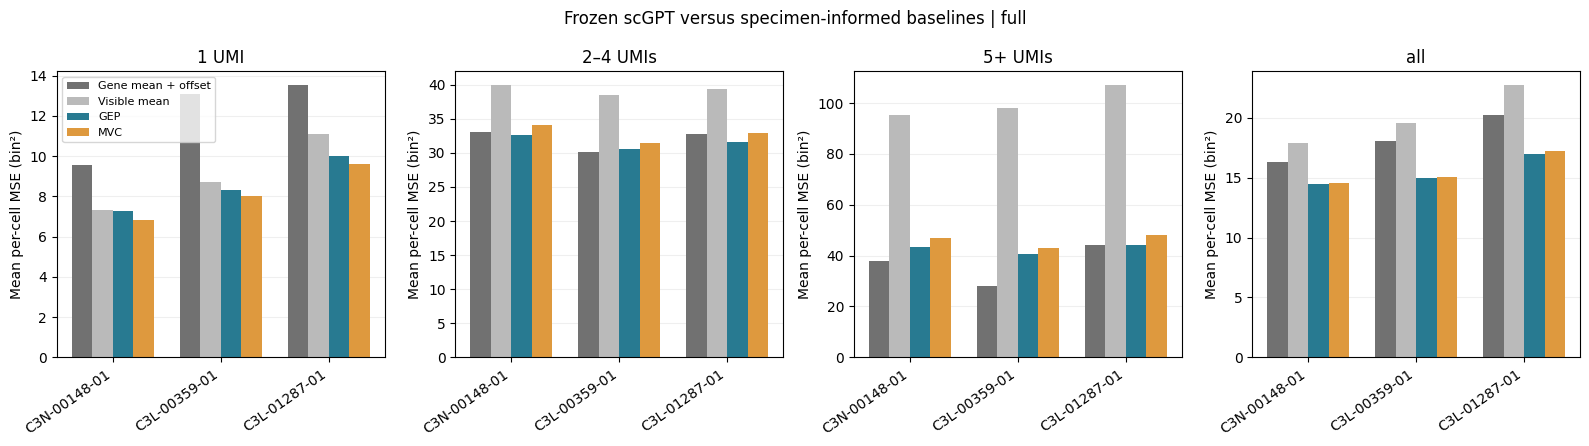

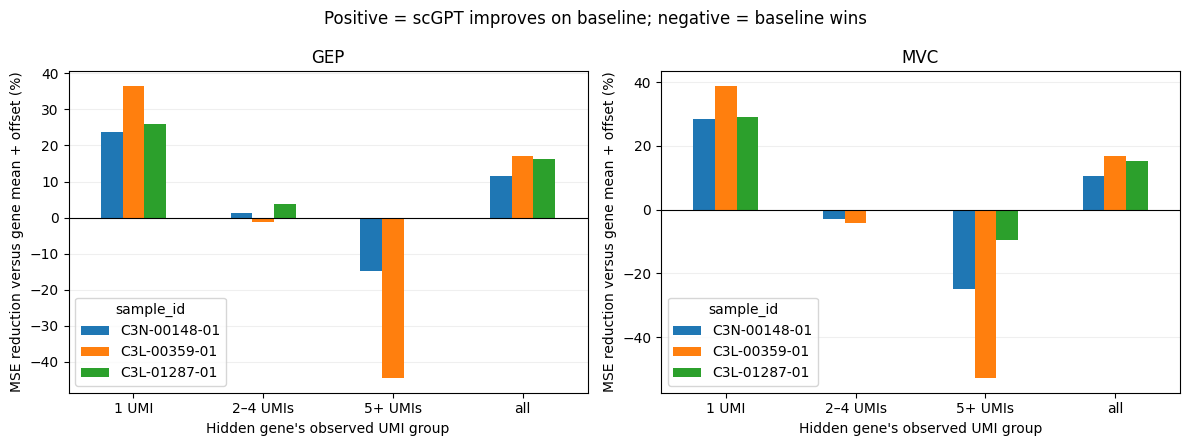

Figures: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/figures


In [9]:
# 8 — Two compact report figures: native-bin loss and advantage over the strong baseline.
import matplotlib.pyplot as plt

figure_dir = RUN_DIR / "figures"
figure_dir.mkdir(exist_ok=True)
sample_order = list(dict.fromkeys(all_summary["sample_id"]))
methods = ["gene_mean_plus_offset", "visible_mean", "GEP", "MVC"]
colors = ["#717171", "#BABABA", "#287A91", "#DE993E"]
labels = ["Gene mean + offset", "Visible mean", "GEP", "MVC"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), squeeze=False)
for ax, group in zip(axes[0], COUNT_GROUPS):
    table = all_summary.loc[all_summary["count_group"].eq(group)].pivot(
        index="sample_id", columns="method", values="mean_MSE").reindex(index=sample_order, columns=methods)
    x = np.arange(len(sample_order))
    width = 0.19
    for k, (method, color, label) in enumerate(zip(methods, colors, labels)):
        ax.bar(x + (k - 1.5) * width, table[method], width, label=label, color=color)
    ax.set_title(group)
    ax.set_xticks(x, sample_order, rotation=35, ha="right")
    ax.set_ylabel("Mean per-cell MSE (bin²)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Frozen scGPT versus specimen-informed baselines | {MODE}")
fig.tight_layout()
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), squeeze=False)
for ax, head in zip(axes[0], ["GEP", "MVC"]):
    table = all_summary.loc[all_summary["method"].eq(head)].pivot(
        index="count_group", columns="sample_id", values="percent_MSE_reduction"
    ).reindex(COUNT_GROUPS)
    table.reindex(columns=sample_order).plot.bar(ax=ax, rot=0)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(head)
    ax.set_xlabel("Hidden gene's observed UMI group")
    ax.set_ylabel("MSE reduction versus gene mean + offset (%)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Positive = scGPT improves on baseline; negative = baseline wins")
fig.tight_layout()
fig.savefig(figure_dir / "relative_gain_by_specimen.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "relative_gain_by_specimen.pdf", bbox_inches="tight")
plt.show()
print("Figures:", figure_dir)


In [10]:
KIDNEY_SUMMARY_FILE = RUN_DIR / "all_specimens_summary.csv"
assert KIDNEY_SUMMARY_FILE.exists()

print("Kidney results:", KIDNEY_SUMMARY_FILE)

Kidney results: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/all_specimens_summary.csv


### 2. Brain

In [11]:
# 1 — Paths and settings: edit this cell only to choose specimens/run size.
from pathlib import Path
from datetime import datetime, timezone
import gc
import gzip
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import sys
import time

import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread
from threadpoolctl import threadpool_limits
import torch
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
LAB_ROOT = Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale")
META = LAB_ROOT / "metadata/sample_md.tsv"
GDC_ROOT = LAB_ROOT / "GDC-data"
MODEL = ROOT / "models/whole-human"
HELPER = ROOT / "notebooks/scgpt_session/scgpt_session.py"
HISTORICAL = ROOT / "sanity_check/reference_4068d67/scgpt"
CENSUS_ANNOTATION = ROOT / "sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"

# Same diagnosis initially; distinct patients. Edit/add IDs after inspecting metadata.
SAMPLE_IDS = [
    "C3L-03405-01",
    "C3N-01798-01",
    "C3N-01816-01",
]
# For example, add "C3L-03405-01" later for a brain/glioblastoma specimen.

# If automatic discovery finds multiple matrices, explicitly set a directory here.
MATRIX_DIR_OVERRIDES = {}       # {"sample-id": Path("/absolute/path/to/mex_directory")}
COPYKAT_OVERRIDES = {}         # Optional: {"sample-id": Path("/absolute/path/to/prediction.txt")}

MODE = "full"                # Change to "full" after checking the pilot.
assert MODE in {"pilot", "full"}
SPLIT_SEED = 42
N_REFERENCE = 128
N_EVALUATION = 128
MASK_FRACTION = 0.25
MASK_SEEDS = [42] if MODE == "pilot" else [42, 43, 44, 45]
MAX_EVALUATED = 8 if MODE == "pilot" else N_EVALUATION
ACTIVE_SAMPLE_IDS = SAMPLE_IDS[:1] if MODE == "pilot" else SAMPLE_IDS
RUN_SHUFFLED = True
SAVE_QUERY_PREDICTIONS = True  # Compressed per-mask files; no dense expression export.
N_THREADS = 4
torch.set_num_threads(N_THREADS)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
RUN_DIR = ROOT / "multicase_expression/results" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

required = [META, HELPER, HISTORICAL / "preprocess.py",
            HISTORICAL / "data_collator.py", CENSUS_ANNOTATION]
required += [MODEL / f for f in ["args.json", "vocab.json", "best_model.pt"]]
for path in required:
    assert path.is_file(), f"Required existing file not found: {path}"
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| threads:", torch.get_num_threads())
print("Mode:", MODE, "| active specimens:", ACTIVE_SAMPLE_IDS)
print("Output:", RUN_DIR)


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
PyTorch: 2.2.2+cpu | threads: 4
Mode: full | active specimens: ['C3L-03405-01', 'C3N-01798-01', 'C3N-01816-01']
Output: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full


In [12]:
# 2 — Pin the preprocessing binding and load every checkpoint tensor strictly.
def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

session = import_file("multicase_verified_session", HELPER)
historical = import_file("multicase_historical_preprocess", HISTORICAL / "preprocess.py")
historical_collator = import_file(
    "scgpt._multicase_historical_collator", HISTORICAL / "data_collator.py"
)
historical_collator.binning = historical.binning
assert historical_collator.binning is historical.binning
assert historical._digitize.__defaults__ == ("one",), "Unexpected tie rule."

model, loaded_vocab, config = session.load_model(MODEL)
model = model.cpu().eval()
vocab = loaded_vocab.get_stoi()
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
pad_id = vocab[config.get("pad_token", "<pad>")]
cls_id = vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value,
    do_mlm=True, do_binning=True, mlm_probability=MASK_FRACTION,
    mask_value=config.get("mask_value", -1), max_length=config["max_seq_len"],
    sampling=True, keep_first_n_tokens=1, data_style="both",
)
print("Helper:", session.__file__)
print("Historical tie rule:", historical._digitize.__defaults__)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b""):
            digest.update(block)
    return digest.hexdigest()

run_manifest = {
    "run_id": RUN_ID, "mode": MODE, "sample_ids": ACTIVE_SAMPLE_IDS,
    "split_seed": SPLIT_SEED, "n_reference": N_REFERENCE,
    "n_evaluation_reserved": N_EVALUATION, "n_evaluated": MAX_EVALUATED,
    "mask_seeds": MASK_SEEDS, "mask_fraction": MASK_FRACTION,
    "run_shuffled": RUN_SHUFFLED, "config": config,
    "helper_path": str(HELPER), "helper_sha256": sha256(HELPER),
    "checkpoint_sha256": sha256(MODEL / "best_model.pt"),
    "vocab_sha256": sha256(MODEL / "vocab.json"),
    "historical_commit": "4068d67caaac1e28d56964da68e0214817e38428",
    "historical_preprocess_sha256": sha256(HISTORICAL / "preprocess.py"),
    "historical_collator_sha256": sha256(HISTORICAL / "data_collator.py"),
    "census_annotation_path": str(CENSUS_ANNOTATION),
    "versions": {p: importlib.metadata.version(p) for p in
                 ["torch", "scgpt", "anndata", "numpy", "scipy", "pandas"]},
    "python": sys.version, "platform": platform.platform(),
    "baseline_scope": "Separate reference cells within each specimen; positive-gene bin means",
    "qc_policy": "No new biological QC exclusions; require enough detected model genes for >=1 query",
    "limitations": [
        "Current specimen has already been explored; new patients are replication data",
        "Only detected genes are queried; zero measurements are not evaluated",
        "Full-profile quantile boundaries use hidden expression values",
        "CopyKAT categories are predictions, not cell-type or malignancy truth",
        "Masks and queried genes within a patient are not independent patients",
        "Pinned preprocessing is verified; exact released checkpoint training commit is unconfirmed",
    ],
}
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))


Strict load: 163 checkpoint tensors; no omitted tensors.
Helper: /home/akash1/scgpt-cna/notebooks/scgpt_session/scgpt_session.py
Historical tie rule: ('one',)


3573

In [13]:
# 3 — Inspect sample identities and discover sparse 10x files, without loading counts.
metadata = pd.read_csv(META, sep="\t", dtype=str)
assert metadata["sample_id"].is_unique
missing = set(SAMPLE_IDS) - set(metadata["sample_id"])
assert not missing, f"IDs absent from sample metadata: {sorted(missing)}"
selected_metadata = metadata.set_index("sample_id").loc[SAMPLE_IDS].reset_index()
assert selected_metadata["case_id"].is_unique, "Choose one specimen per patient initially."

def sidecar(directory, stem):
    candidates = [directory / stem, directory / (stem + ".gz")]
    found = [p for p in candidates if p.is_file()]
    assert len(found) == 1, f"Expected one {stem}(.gz) in {directory}; found {found}"
    return found[0]

def discover_sample(record):
    sid, case = record["sample_id"], record["case_id"]
    sample_dir = GDC_ROOT / case / sid
    assert sample_dir.is_dir(), f"Missing sample directory: {sample_dir}"
    if sid in MATRIX_DIR_OVERRIDES:
        matrix_dir = Path(MATRIX_DIR_OVERRIDES[sid])
    else:
        # Search only this specimen's single_cell subtree; ignore dense CSVs/archives.
        candidates = sorted({p.parent for p in (sample_dir / "single_cell").rglob("matrix.mtx*")
                             if p.name in {"matrix.mtx", "matrix.mtx.gz"}})
        filtered = [p for p in candidates if "filtered" in str(p).lower()
                    and "raw_feature" not in str(p).lower()]
        if filtered:
            candidates = filtered
        assert len(candidates) == 1, (
            f"Ambiguous/missing MEX directory for {sid}: {candidates}. "
            "Set MATRIX_DIR_OVERRIDES explicitly. Do not choose a raw droplet matrix."
        )
        matrix_dir = candidates[0]
    ck = ([Path(COPYKAT_OVERRIDES[sid])] if sid in COPYKAT_OVERRIDES else
          sorted((sample_dir / "single_cell").rglob("*copykat_prediction.txt")))
    assert len(ck) <= 1, f"Multiple CopyKAT files for {sid}; set COPYKAT_OVERRIDES."
    if ck:
        assert ck[0].is_file()
    return {
        **record, "sample_directory": str(sample_dir),
        "matrix_file": str(sidecar(matrix_dir, "matrix.mtx")),
        "features_file": str(sidecar(matrix_dir, "features.tsv")),
        "barcodes_file": str(sidecar(matrix_dir, "barcodes.tsv")),
        "copykat_file": str(ck[0]) if ck else "",
    }

manifest = pd.DataFrame([discover_sample(r) for r in selected_metadata.to_dict("records")])
display(manifest[["case_id", "sample_id", "primary_site",
                  "diagnoses.0.primary_diagnosis", "wgd_status", "matrix_file"]])
manifest.to_csv(RUN_DIR / "sample_manifest.tsv", sep="\t", index=False)
print("All selected specimens have an unambiguous sparse matrix.")


,case_id,sample_id,primary_site,diagnoses.0.primary_diagnosis,wgd_status,matrix_file
0,C3L-03405,C3L-03405-01,Brain,Glioblastoma,WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
1,C3N-01798,C3N-01798-01,Brain,Glioblastoma,WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
2,C3N-01816,C3N-01816-01,Brain,Glioblastoma,WGD-,/home/akash1/projects/rrg-tperkins/dgladish/Pr...


All selected specimens have an unambiguous sparse matrix.


In [14]:
# 4 — Load the shared annotation map; define sparse loading and harmonization.
# Census counts are never read here. Feature IDs connect alternative gene symbols.
census_annotation = ad.read_h5ad(CENSUS_ANNOTATION, backed="r")
census_var = census_annotation.var[["feature_id", "feature_name"]].copy()
census_annotation.file.close()
del census_annotation

def base_ids(values):
    # Strip only terminal Ensembl version numbers. Keep PAR_Y identities separate.
    return pd.Series(values, dtype="string").str.replace(r"\.\d+$", "", regex=True)

census_var["ensembl_base"] = base_ids(census_var["feature_id"].to_numpy()).to_numpy()
symbol_counts = census_var.groupby("ensembl_base")["feature_name"].nunique()
unambiguous_ids = symbol_counts.index[symbol_counts.eq(1)]
id_to_symbol = (
    census_var.loc[census_var["ensembl_base"].isin(unambiguous_ids)]
    .drop_duplicates("ensembl_base").set_index("ensembl_base")["feature_name"]
)
print("Unambiguous annotation IDs:", len(id_to_symbol))
print("Ambiguous IDs excluded:", int(symbol_counts.gt(1).sum()))

def load_lab_sample(record):
    started = time.perf_counter()
    features = pd.read_csv(record["features_file"], sep="\t", header=None, dtype=str)
    barcodes = pd.read_csv(record["barcodes_file"], sep="\t", header=None, dtype=str)[0]
    assert features.shape[1] >= 3 and barcodes.is_unique
    with threadpool_limits(limits=N_THREADS):
        matrix_path = Path(record["matrix_file"])
        if matrix_path.suffix == ".gz":
            with gzip.open(matrix_path, "rb") as stream:
                raw = mmread(stream).T.tocsr()
        else:
            raw = mmread(matrix_path).T.tocsr()
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == (len(barcodes), len(features))
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected integer UMI counts."
    gex = features[2].eq("Gene Expression").to_numpy()
    assert gex.any()
    raw = raw[:, gex].tocsr()
    var = features.loc[gex, [0, 1, 2]].reset_index(drop=True)
    var.columns = ["gene_id", "gene_symbol", "feature_type"]
    assert var["gene_id"].is_unique, "Duplicate feature IDs require an explicit resolution."
    var["ensembl_base"] = base_ids(var["gene_id"]).to_numpy()
    var["census_symbol"] = var["ensembl_base"].map(id_to_symbol)
    # Prefer a recognized ID-matched Census symbol; otherwise retain a recognized lab symbol.
    mapped_ok = var["census_symbol"].isin(vocab)
    var["model_symbol"] = var["census_symbol"].where(mapped_ok, var["gene_symbol"])
    original_keep = var["gene_symbol"].isin(vocab) & ~var["gene_symbol"].duplicated()
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    columns = np.flatnonzero(keep.to_numpy())
    gene_info = var.iloc[columns].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, columns].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = pd.DataFrame(index=pd.Index(barcodes.to_numpy(), name="barcode"))
    obs["cell_index"] = np.arange(len(obs))
    obs["case_id"], obs["sample_id"] = record["case_id"], record["sample_id"]
    obs["cell_id"] = record["sample_id"] + ":" + obs.index.astype(str)
    obs["tissue"] = record["primary_site"]
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["sample_wgd_status"] = record["wgd_status"]
    obs["cell_type"] = "unassigned"
    obs["malignant_status"] = "unresolved"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mt_columns = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = (100 * np.asarray(raw[:, mt_columns].sum(axis=1)).ravel()
                            / obs["total_counts"].replace(0, np.nan))
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = (np.asarray(ones.sum(axis=1)).ravel()
                                  / obs["detected_genes"].replace(0, np.nan))
    del ones

    # Full-profile, deterministic model-bin summaries for each cell.
    model_singletons, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i + 1]]
        if not len(counts):
            model_singletons.append(np.nan); occupied.append(0)
            dominant.append(np.nan); singleton_bin.append(np.nan)
            continue
        labels = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(labels, return_counts=True)
        one = counts == 1
        model_singletons.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(labels)))
        singleton_bin.append(float(labels[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = model_singletons
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin

    obs["copykat_group"] = "missing_from_output"
    unmatched_copykat_barcodes = 0
    if record["copykat_file"]:
        ck = pd.read_csv(record["copykat_file"], sep="\t", dtype=str)
        assert {"cell.names", "copykat.pred"}.issubset(ck.columns)
        assert ck["cell.names"].is_unique
        unmatched_copykat_barcodes = int((~ck["cell.names"].isin(obs.index)).sum())
        obs["copykat_group"] = (ck.set_index("cell.names")["copykat.pred"]
                                 .reindex(obs.index).fillna("missing_from_output"))
    # Clusters, when already downloaded, are retained as cluster IDs, not cell types.
    obs["seurat_cluster"] = "not_available"
    seurat_path = ROOT / "measurement_analysis" / record["sample_id"] / "gdc_secondary_analysis/seurat.analysis.tsv"
    if seurat_path.is_file():
        seurat = pd.read_csv(seurat_path, sep="\t", dtype=str)
        assert {"cell_barcode", "seurat_cluster"}.issubset(seurat.columns)
        assert seurat["cell_barcode"].is_unique
        obs["seurat_cluster"] = (seurat.set_index("cell_barcode")["seurat_cluster"]
                                   .reindex(obs.index).fillna("not_available"))

    total = float(raw.sum())
    report = {
        "sample_id": record["sample_id"], "case_id": record["case_id"],
        "tissue": record["primary_site"], "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(raw[:, original_keep.to_numpy()].sum()) / total,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": unmatched_copykat_barcodes,
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    del raw
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


Unambiguous annotation IDs: 60664
Ambiguous IDs excluded: 0


In [15]:
# 5 — Independent reference cells, native-bin baselines and verified model inputs.
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]

def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])

def reserve_cells(obs):
    minimum_genes = max(2, int(np.ceil(1 / MASK_FRACTION)))
    eligible = np.flatnonzero(obs["model_detected_genes"].to_numpy() >= minimum_genes)
    assert len(eligible) >= N_REFERENCE + N_EVALUATION, (
        f"Only {len(eligible)} eligible cells; need {N_REFERENCE + N_EVALUATION}. "
        "If reducing the budget, use the same setting for all specimens."
    )
    order = np.random.default_rng(SPLIT_SEED).permutation(eligible)
    reference = order[:N_REFERENCE]
    evaluation = order[N_REFERENCE:N_REFERENCE + N_EVALUATION]
    assert not set(reference) & set(evaluation)
    return reference, evaluation

def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

def make_example(matrix, gene_ids, i):
    row = matrix.getrow(int(i))
    return {
        "genes": torch.tensor(np.concatenate(([cls_id], gene_ids[row.indices])), dtype=torch.long),
        "expressions": torch.tensor(np.concatenate(([pad_value], row.data)), dtype=torch.float32),
    }

def make_batch(matrix, gene_ids, evaluation, seed):
    # Always collate ALL reserved cells, even for an eight-cell pilot. The collator
    # chooses lengths using the batch. Fresh examples avoid in-place double binning.
    old_np = np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            np.random.seed(seed)
            return collator([make_example(matrix, gene_ids, i) for i in evaluation])
    finally:
        np.random.set_state(old_np)

def verified_input(matrix, gene_ids, batch, j, i):
    vm = batch["pcpt_gene"][j].ne(pad_id)
    qm = batch["gen_gene"][j].ne(pad_id)
    known_ids = batch["pcpt_gene"][j, vm]
    known_values = batch["pcpt_expr"][j, vm]
    query_ids = batch["gen_gene"][j, qm]
    target = batch["gen_expr_target"][j, qm].cpu().numpy().astype(float)
    assert int(known_ids[0]) == cls_id and float(known_values[0]) == pad_value
    assert len(query_ids) and len(known_ids) > 1
    assert cls_id not in query_ids.tolist()
    assert len(known_ids) + len(query_ids) <= config["max_seq_len"]
    row = matrix.getrow(int(i))
    tokens = gene_ids[row.indices]
    positions = {int(t): k for k, t in enumerate(tokens)}
    vi = np.array([positions[t] for t in known_ids[1:].tolist()], dtype=int)
    qi = np.array([positions[t] for t in query_ids.tolist()], dtype=int)
    assert len(set(vi)) == len(vi) and len(set(qi)) == len(qi)
    assert not np.intersect1d(vi, qi).size
    native = np.asarray(historical.binning(row.data.copy(), n_bins=51))
    np.testing.assert_array_equal(native[vi], known_values[1:].cpu().numpy())
    np.testing.assert_array_equal(native[qi], target)
    # Independent quantile/search check, in addition to the historical implementation.
    edges = np.quantile(row.data, np.linspace(0, 1, 50))
    np.testing.assert_array_equal(native, np.searchsorted(edges, row.data, side="right"))
    return known_ids, known_values, query_ids, target, row, vi, qi

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = model(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def summarize_scores(scores):
    # Average masks WITHIN each cell first. A cell has one weight in each group.
    keys = ["sample_id", "case_id", "cell_id", "cell_index", "method", "count_group"]
    per_cell = scores.groupby(keys, as_index=False).agg(
        MSE=("MSE", "mean"), MAE=("MAE", "mean"),
        mean_residual=("mean_residual", "mean"), target_std=("target_std", "mean"),
        prediction_std=("prediction_std", "mean"),
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
    )
    baseline = per_cell.loc[per_cell["method"].eq("gene_mean_plus_offset"),
                           ["cell_id", "count_group", "MSE"]].rename(columns={"MSE": "baseline_MSE"})
    per_cell = per_cell.merge(baseline, on=["cell_id", "count_group"], validate="many_to_one")
    per_cell["MSE_gain"] = per_cell["baseline_MSE"] - per_cell["MSE"]
    summary = per_cell.groupby(["sample_id", "case_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"),
        median_MSE=("MSE", "median"), mean_MAE=("MAE", "mean"),
        mean_MSE_gain=("MSE_gain", "mean"), cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
    )
    # This is a ratio of mean losses, not an average of per-cell percentages.
    summary["mean_baseline_MSE"] = summary["mean_MSE"] + summary["mean_MSE_gain"]
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    return per_cell, summary


In [16]:
# 6 — Run the pilot/full benchmark. Sparse matrices are processed one specimen at a time.
def run_sample(record):
    sid = record["sample_id"]
    destination = RUN_DIR / sid
    destination.mkdir(exist_ok=True)
    started = time.perf_counter()
    print(f"\nLoading {sid}: {record['primary_site']} | {record['diagnoses.0.primary_diagnosis']}", flush=True)
    matrix, gene_ids, gene_info, obs, report = load_lab_sample(record)
    reference, reserved_evaluation = reserve_cells(obs)
    evaluation = reserved_evaluation[:MAX_EVALUATED]
    means, support, constant = fit_baseline(matrix, reference)

    obs["split"] = "unused"
    obs.iloc[reference, obs.columns.get_loc("split")] = "reference"
    obs.iloc[reserved_evaluation, obs.columns.get_loc("split")] = "evaluation_reserved"
    obs["evaluated_this_run"] = obs["cell_index"].isin(evaluation)
    obs.to_csv(destination / "cell_metadata_and_splits.tsv", sep="\t")
    gene_info.assign(gene_token=gene_ids, reference_support=support, reference_mean=means).to_csv(
        destination / "gene_mapping_and_baseline.tsv.gz", sep="\t", index=False)
    report.update({"reference_constant": constant, "n_reference": len(reference),
                   "n_evaluated": len(evaluation), "n_reserved_evaluation": len(reserved_evaluation)})
    print(f"Cells {len(obs):,}; model features {matrix.shape[1]:,}; "
          f"counts retained {report['harmonized_percent_counts']:.4f}%", flush=True)
    print(f"Reference {len(reference)}; reserved evaluation {len(reserved_evaluation)}; "
          f"running {len(evaluation)}; reference constant {constant:.3f}", flush=True)
    display(obs.iloc[evaluation[:8]][["case_id", "sample_id", "copykat_group", "total_counts",
                                      "detected_genes", "model_count_fraction", "pct_counts_mt"]])
    score_rows = []
    for seed in MASK_SEEDS:
        batch = make_batch(matrix, gene_ids, reserved_evaluation, seed)
        query_frames = []
        for j, i in enumerate(evaluation):
            ki, kv, qi_tokens, target, row, vi, qi = verified_input(
                matrix, gene_ids, batch, j, int(i))
            query_mean = means[row.indices[qi]]
            # All target-specimen adaptation uses VISIBLE labels only.
            offset = float((kv[1:].cpu().numpy() - means[row.indices[vi]]).mean())
            predictions = {
                "gene_mean": query_mean,
                "gene_mean_plus_offset": query_mean + offset,
                "reference_constant": np.full(len(target), constant),
                "visible_mean": np.full(len(target), float(kv[1:].mean())),
                **predict(ki, kv, qi_tokens),
            }
            if RUN_SHUFFLED:
                shuffle_rng = np.random.default_rng(np.random.SeedSequence([2026, seed, int(i)]))
                shuffled_values = kv.clone()
                shuffled_values[1:] = torch.as_tensor(
                    shuffle_rng.permutation(kv[1:].cpu().numpy()), dtype=kv.dtype)
                predictions.update({head + "_shuffled": p for head, p in
                                    predict(ki, shuffled_values, qi_tokens).items()})
            identity = {"sample_id": sid, "case_id": record["case_id"],
                        "cell_id": obs.iloc[i]["cell_id"], "cell_index": int(i), "mask_seed": seed}
            score_rows.extend(score_predictions(
                predictions, target, row.data[qi], support[row.indices[qi]],
                {**identity, "n_visible_genes": len(vi), "n_query_genes": len(qi),
                 "visible_offset": offset, "copykat_group": obs.iloc[i]["copykat_group"]}))
            if SAVE_QUERY_PREDICTIONS:
                query_frames.append(pd.DataFrame({
                    **identity, "gene_token": qi_tokens.cpu().numpy(),
                    "original_umi": row.data[qi].astype(int), "target_bin": target,
                    "reference_support": support[row.indices[qi]], **predictions,
                }))
            if (j + 1) % 16 == 0 or j + 1 == len(evaluation):
                print(f"{sid} | mask {seed} | completed {j + 1}/{len(evaluation)}", flush=True)
        if query_frames:
            pd.concat(query_frames, ignore_index=True).to_csv(
                destination / f"query_predictions_mask{seed}.csv.gz", index=False)
        del batch, query_frames
        # Preserve completed masks if a later mask is interrupted.
        pd.DataFrame(score_rows).to_csv(destination / "scores_by_cell_mask_group.csv", index=False)

    scores = pd.DataFrame(score_rows)
    per_cell, summary = summarize_scores(scores)
    details = obs.reset_index()[["cell_id", "barcode", "copykat_group", "seurat_cluster",
                                "total_counts", "detected_genes", "model_detected_genes",
                                "fraction_count_one", "model_fraction_count_one", "pct_counts_mt",
                                "model_count_fraction", "occupied_bins", "dominant_bin_fraction"]]
    per_cell = per_cell.merge(details, on="cell_id", validate="many_to_one")
    per_cell.to_csv(destination / "scores_by_cell.csv", index=False)
    summary.to_csv(destination / "summary_by_count_group.csv", index=False)
    report["elapsed_seconds"] = time.perf_counter() - started
    (destination / "sample_audit.json").write_text(json.dumps(report, indent=2))
    print(f"Finished {sid}: {report['elapsed_seconds']:.1f} seconds", flush=True)
    display(summary.loc[summary["count_group"].eq("all")].round(3))
    del matrix
    gc.collect()
    return {"audit": report, "obs": obs, "per_cell": per_cell, "summary": summary}

results = []
for record in manifest.loc[manifest["sample_id"].isin(ACTIVE_SAMPLE_IDS)].to_dict("records"):
    results.append(run_sample(record))
print("\nSaved to:", RUN_DIR)



Loading C3L-03405-01: Brain | Glioblastoma
Cells 5,631; model features 60,566; counts retained 99.9897%
Reference 128; reserved evaluation 128; running 128; reference constant 39.433


,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
TGATGGTCATTACTCT-1,C3L-03405,C3L-03405-01,diploid,858,692,1.000000,1.515152
TGGAACTTCATTGCTT-1,C3L-03405,C3L-03405-01,not.defined,2335,1389,0.999572,1.284797
ATCTTCAGTCATACCA-1,C3L-03405,C3L-03405-01,aneuploid,3759,2061,0.999734,0.478851
CATTCATAGAAGTCCG-1,C3L-03405,C3L-03405-01,diploid,972,778,1.000000,0.925926
AGCTTCCTCGGTCGGT-1,C3L-03405,C3L-03405-01,aneuploid,2070,1409,1.000000,1.352657
GATGAGGCACCTAAAC-1,C3L-03405,C3L-03405-01,diploid,3659,2109,0.999727,0.901886
CCTTGTGGTCACAGAG-1,C3L-03405,C3L-03405-01,diploid,2720,1788,0.999632,3.272059
CTGTGGGTCTGCTGAA-1,C3L-03405,C3L-03405-01,diploid,4212,2267,1.000000,0.451092


C3L-03405-01 | mask 42 | completed 16/128
C3L-03405-01 | mask 42 | completed 32/128
C3L-03405-01 | mask 42 | completed 48/128
C3L-03405-01 | mask 42 | completed 64/128
C3L-03405-01 | mask 42 | completed 80/128
C3L-03405-01 | mask 42 | completed 96/128
C3L-03405-01 | mask 42 | completed 112/128
C3L-03405-01 | mask 42 | completed 128/128
C3L-03405-01 | mask 43 | completed 16/128
C3L-03405-01 | mask 43 | completed 32/128
C3L-03405-01 | mask 43 | completed 48/128
C3L-03405-01 | mask 43 | completed 64/128
C3L-03405-01 | mask 43 | completed 80/128
C3L-03405-01 | mask 43 | completed 96/128
C3L-03405-01 | mask 43 | completed 112/128
C3L-03405-01 | mask 43 | completed 128/128
C3L-03405-01 | mask 44 | completed 16/128
C3L-03405-01 | mask 44 | completed 32/128
C3L-03405-01 | mask 44 | completed 48/128
C3L-03405-01 | mask 44 | completed 64/128
C3L-03405-01 | mask 44 | completed 80/128
C3L-03405-01 | mask 44 | completed 96/128
C3L-03405-01 | mask 44 | completed 112/128
C3L-03405-01 | mask 44 | comp

,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction
24,C3L-03405-01,C3L-03405,all,GEP,128,10.766,6.906,2.367,5.342,128,16.107,33.163
25,C3L-03405-01,C3L-03405,all,GEP_shuffled,128,12.119,7.085,2.755,3.988,121,16.107,24.761
26,C3L-03405-01,C3L-03405,all,MVC,128,10.795,6.926,2.275,5.312,128,16.107,32.981
27,C3L-03405-01,C3L-03405,all,MVC_shuffled,128,11.914,7.005,2.628,4.193,124,16.107,26.032
28,C3L-03405-01,C3L-03405,all,gene_mean,128,25.085,19.740,4.017,-8.978,3,16.107,-55.739
29,C3L-03405-01,C3L-03405,all,gene_mean_plus_offset,128,16.107,11.818,3.128,0.000,0,16.107,0.000
30,C3L-03405-01,C3L-03405,all,reference_constant,128,24.992,18.424,4.116,-8.885,19,16.107,-55.162
31,C3L-03405-01,C3L-03405,all,visible_mean,128,14.102,7.973,2.778,2.006,89,16.107,12.452



Loading C3N-01798-01: Brain | Glioblastoma
Cells 13,089; model features 60,566; counts retained 99.9846%
Reference 128; reserved evaluation 128; running 128; reference constant 34.875


,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
CGAGAAGGTGAGATCG-1,C3N-01798,C3N-01798-01,aneuploid,7323,3357,1.000000,0.682780
GCATCGGGTCATCGCG-1,C3N-01798,C3N-01798-01,diploid,7139,2985,0.999720,0.112061
ACAAAGACAGACAAGC-1,C3N-01798,C3N-01798-01,aneuploid,11041,4310,0.999909,1.104972
TGAATCGAGTCTTCGA-1,C3N-01798,C3N-01798-01,aneuploid,9761,3750,0.999898,1.546973
AGTCATGAGAGCCGTA-1,C3N-01798,C3N-01798-01,aneuploid,4102,2422,1.000000,0.511945
CTCCTCCCAGGCCCTA-1,C3N-01798,C3N-01798-01,aneuploid,22441,5583,0.999822,0.298561
GAAGGACCAGGGCTTC-1,C3N-01798,C3N-01798-01,aneuploid,3417,2119,1.000000,0.643840
TGCATGATCTTCGCTG-1,C3N-01798,C3N-01798-01,aneuploid,12238,3403,1.000000,0.637359


... (3 outputs left out)

,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
ACGGTTATCTCGCCTA-1,C3N-01816,C3N-01816-01,aneuploid,28145,6800,0.999858,0.824303
CTATAGGAGCACTAGG-1,C3N-01816,C3N-01816-01,diploid,3857,1990,1.000000,1.270417
GCGTGCAGTCCCACGA-1,C3N-01816,C3N-01816-01,aneuploid,4214,2376,1.000000,0.830565
GCCATGGGTTGTGGCC-1,C3N-01816,C3N-01816-01,aneuploid,4544,2371,0.999780,12.500000
AACAAGATCTAAACGC-1,C3N-01816,C3N-01816-01,aneuploid,3925,2046,0.999745,0.203822
ATTACTCGTCTCTCTG-1,C3N-01816,C3N-01816-01,aneuploid,14616,4728,0.999932,0.116311
TCTGTCGTCTGGAGAG-1,C3N-01816,C3N-01816-01,diploid,2521,1627,0.999603,4.046013
TTACCATCATCCCGTT-1,C3N-01816,C3N-01816-01,diploid,4006,2240,1.000000,0.848727


C3N-01816-01 | mask 42 | completed 16/128
C3N-01816-01 | mask 42 | completed 32/128
C3N-01816-01 | mask 42 | completed 48/128
C3N-01816-01 | mask 42 | completed 64/128
C3N-01816-01 | mask 42 | completed 80/128
C3N-01816-01 | mask 42 | completed 96/128
C3N-01816-01 | mask 42 | completed 112/128
C3N-01816-01 | mask 42 | completed 128/128
C3N-01816-01 | mask 43 | completed 16/128
C3N-01816-01 | mask 43 | completed 32/128
C3N-01816-01 | mask 43 | completed 48/128
C3N-01816-01 | mask 43 | completed 64/128
C3N-01816-01 | mask 43 | completed 80/128
C3N-01816-01 | mask 43 | completed 96/128
C3N-01816-01 | mask 43 | completed 112/128
C3N-01816-01 | mask 43 | completed 128/128
C3N-01816-01 | mask 44 | completed 16/128
C3N-01816-01 | mask 44 | completed 32/128
C3N-01816-01 | mask 44 | completed 48/128
C3N-01816-01 | mask 44 | completed 64/128
C3N-01816-01 | mask 44 | completed 80/128
C3N-01816-01 | mask 44 | completed 96/128
C3N-01816-01 | mask 44 | completed 112/128
C3N-01816-01 | mask 44 | comp

,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction
24,C3N-01816-01,C3N-01816,all,GEP,128,22.381,21.787,3.700,3.635,100,26.016,13.973
25,C3N-01816-01,C3N-01816,all,GEP_shuffled,128,26.681,24.224,4.513,-0.665,62,26.016,-2.556
26,C3N-01816-01,C3N-01816,all,MVC,128,22.588,21.990,3.677,3.428,97,26.016,13.177
27,C3N-01816-01,C3N-01816,all,MVC_shuffled,128,26.767,24.289,4.470,-0.751,62,26.016,-2.887
28,C3N-01816-01,C3N-01816,all,gene_mean,128,31.306,28.056,4.549,-5.290,15,26.016,-20.334
29,C3N-01816-01,C3N-01816,all,gene_mean_plus_offset,128,26.016,24.087,4.097,0.000,0,26.016,0.000
30,C3N-01816-01,C3N-01816,all,reference_constant,128,39.844,33.091,5.180,-13.828,2,26.016,-53.153
31,C3N-01816-01,C3N-01816,all,visible_mean,128,31.816,29.181,4.860,-5.800,36,26.016,-22.296



Saved to: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full


In [17]:
# 7 — Compare performance and measurement profiles, keeping specimens separate.
all_summary = pd.concat([r["summary"] for r in results], ignore_index=True)
all_per_cell = pd.concat([r["per_cell"] for r in results], ignore_index=True)
all_obs = pd.concat([r["obs"].reset_index() for r in results], ignore_index=True)
all_audits = pd.DataFrame([r["audit"] for r in results])
all_summary.to_csv(RUN_DIR / "all_specimens_summary.csv", index=False)
all_per_cell.to_csv(RUN_DIR / "all_specimens_cell_scores.csv", index=False)
all_audits.to_csv(RUN_DIR / "all_specimens_audit.csv", index=False)

print("Overall scores: one vote per cell, with masks averaged first")
display(all_summary.query("count_group == 'all'")[[
    "sample_id", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction", "cells_beating_baseline"
]].sort_values(["sample_id", "mean_MSE"]).round(3))

print("GEP/MVC by count group; positive gain means better than gene mean + offset")
display(all_summary.loc[all_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

profile_metrics = ["total_counts", "detected_genes", "model_detected_genes", "fraction_count_one",
                   "model_count_fraction", "occupied_bins", "dominant_bin_fraction", "pct_counts_mt"]
profile_parts = []
for label, frame in [("all_loaded_cells", all_obs),
                     ("evaluated_cells", all_obs.loc[all_obs["evaluated_this_run"]])]:
    part = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"])[profile_metrics].median()
    part["n_cells"] = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"]).size()
    part["population"] = label
    profile_parts.append(part.reset_index())
profiles = pd.concat(profile_parts, ignore_index=True)
profiles.to_csv(RUN_DIR / "measurement_profile_medians.csv", index=False)
print("Measurement profiles: compare the evaluation subset as well as the full specimen")
display(profiles.round(3))

print("Query coverage per group; repeated masks are query EVENTS, not independent cells")
coverage = (all_per_cell.query("method == 'GEP'")
            .groupby(["sample_id", "count_group"], as_index=False)
            .agg(cells=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)


Overall scores: one vote per cell, with masks averaged first


,sample_id,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction,cells_beating_baseline
24,C3L-03405-01,GEP,128,10.766,2.367,5.342,33.163,128
26,C3L-03405-01,MVC,128,10.795,2.275,5.312,32.981,128
27,C3L-03405-01,MVC_shuffled,128,11.914,2.628,4.193,26.032,124
25,C3L-03405-01,GEP_shuffled,128,12.119,2.755,3.988,24.761,121
31,C3L-03405-01,visible_mean,128,14.102,2.778,2.006,12.452,89
29,C3L-03405-01,gene_mean_plus_offset,128,16.107,3.128,0.000,0.000,0
30,C3L-03405-01,reference_constant,128,24.992,4.116,-8.885,-55.162,19
28,C3L-03405-01,gene_mean,128,25.085,4.017,-8.978,-55.739,3
56,C3N-01798-01,GEP,128,27.938,4.210,5.144,15.548,121
58,C3N-01798-01,MVC,128,28.179,4.209,4.903,14.820,123


GEP/MVC by count group; positive gain means better than gene mean + offset


,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,C3L-03405-01,1 UMI,GEP,128,6.005,6.208,50.833
2,C3L-03405-01,1 UMI,MVC,128,5.507,6.706,54.909
8,C3L-03405-01,2–4 UMIs,GEP,128,24.513,0.851,3.356
10,C3L-03405-01,2–4 UMIs,MVC,128,26.138,-0.774,-3.051
16,C3L-03405-01,5+ UMIs,GEP,127,31.525,-2.386,-8.187
18,C3L-03405-01,5+ UMIs,MVC,127,34.251,-5.111,-17.540
24,C3L-03405-01,all,GEP,128,10.766,5.342,33.163
26,C3L-03405-01,all,MVC,128,10.795,5.312,32.981
32,C3N-01798-01,1 UMI,GEP,128,20.627,6.602,24.247
34,C3N-01798-01,1 UMI,MVC,128,19.677,7.552,27.736


Measurement profiles: compare the evaluation subset as well as the full specimen


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,C3L-03405-01,C3L-03405,Brain,Glioblastoma,1465.0,1052.0,1052.0,0.813,1.0,5.0,0.813,1.751,5631,all_loaded_cells
1,C3N-01798-01,C3N-01798,Brain,Glioblastoma,5771.0,2690.0,2689.0,0.615,1.0,8.0,0.614,0.910,13089,all_loaded_cells
2,C3N-01816-01,C3N-01816,Brain,Glioblastoma,5101.0,2591.0,2591.0,0.670,1.0,7.0,0.670,1.643,16977,all_loaded_cells
3,C3L-03405-01,C3L-03405,Brain,Glioblastoma,1552.0,1139.0,1139.0,0.806,1.0,5.0,0.806,1.693,128,evaluated_cells
4,C3N-01798-01,C3N-01798,Brain,Glioblastoma,5732.5,2639.5,2639.0,0.616,1.0,8.0,0.616,0.657,128,evaluated_cells
5,C3N-01816-01,C3N-01816,Brain,Glioblastoma,5094.5,2600.5,2600.0,0.667,1.0,7.0,0.667,1.353,128,evaluated_cells


Query coverage per group; repeated masks are query EVENTS, not independent cells


,sample_id,count_group,cells,query_events
0,C3L-03405-01,1 UMI,128,95590
1,C3L-03405-01,2–4 UMIs,128,26258
2,C3L-03405-01,5+ UMIs,127,4044
3,C3L-03405-01,all,128,125892
4,C3N-01798-01,1 UMI,128,94074
5,C3N-01798-01,2–4 UMIs,128,45646
6,C3N-01798-01,5+ UMIs,128,12708
7,C3N-01798-01,all,128,152428
8,C3N-01816-01,1 UMI,128,99927
9,C3N-01816-01,2–4 UMIs,128,41882


In [18]:
# 7 — Compare performance and measurement profiles, keeping specimens separate.
all_summary = pd.concat([r["summary"] for r in results], ignore_index=True)
all_per_cell = pd.concat([r["per_cell"] for r in results], ignore_index=True)
all_obs = pd.concat([r["obs"].reset_index() for r in results], ignore_index=True)
all_audits = pd.DataFrame([r["audit"] for r in results])
all_summary.to_csv(RUN_DIR / "all_specimens_summary.csv", index=False)
all_per_cell.to_csv(RUN_DIR / "all_specimens_cell_scores.csv", index=False)
all_audits.to_csv(RUN_DIR / "all_specimens_audit.csv", index=False)

print("Overall scores: one vote per cell, with masks averaged first")
display(all_summary.query("count_group == 'all'")[[
    "sample_id", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction", "cells_beating_baseline"
]].sort_values(["sample_id", "mean_MSE"]).round(3))

print("GEP/MVC by count group; positive gain means better than gene mean + offset")
display(all_summary.loc[all_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

profile_metrics = ["total_counts", "detected_genes", "model_detected_genes", "fraction_count_one",
                   "model_count_fraction", "occupied_bins", "dominant_bin_fraction", "pct_counts_mt"]
profile_parts = []
for label, frame in [("all_loaded_cells", all_obs),
                     ("evaluated_cells", all_obs.loc[all_obs["evaluated_this_run"]])]:
    part = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"])[profile_metrics].median()
    part["n_cells"] = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"]).size()
    part["population"] = label
    profile_parts.append(part.reset_index())
profiles = pd.concat(profile_parts, ignore_index=True)
profiles.to_csv(RUN_DIR / "measurement_profile_medians.csv", index=False)
print("Measurement profiles: compare the evaluation subset as well as the full specimen")
display(profiles.round(3))

print("Query coverage per group; repeated masks are query EVENTS, not independent cells")
coverage = (all_per_cell.query("method == 'GEP'")
            .groupby(["sample_id", "count_group"], as_index=False)
            .agg(cells=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)


Overall scores: one vote per cell, with masks averaged first


,sample_id,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction,cells_beating_baseline
24,C3L-03405-01,GEP,128,10.766,2.367,5.342,33.163,128
26,C3L-03405-01,MVC,128,10.795,2.275,5.312,32.981,128
27,C3L-03405-01,MVC_shuffled,128,11.914,2.628,4.193,26.032,124
25,C3L-03405-01,GEP_shuffled,128,12.119,2.755,3.988,24.761,121
31,C3L-03405-01,visible_mean,128,14.102,2.778,2.006,12.452,89
29,C3L-03405-01,gene_mean_plus_offset,128,16.107,3.128,0.000,0.000,0
30,C3L-03405-01,reference_constant,128,24.992,4.116,-8.885,-55.162,19
28,C3L-03405-01,gene_mean,128,25.085,4.017,-8.978,-55.739,3
56,C3N-01798-01,GEP,128,27.938,4.210,5.144,15.548,121
58,C3N-01798-01,MVC,128,28.179,4.209,4.903,14.820,123


GEP/MVC by count group; positive gain means better than gene mean + offset


,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,C3L-03405-01,1 UMI,GEP,128,6.005,6.208,50.833
2,C3L-03405-01,1 UMI,MVC,128,5.507,6.706,54.909
8,C3L-03405-01,2–4 UMIs,GEP,128,24.513,0.851,3.356
10,C3L-03405-01,2–4 UMIs,MVC,128,26.138,-0.774,-3.051
16,C3L-03405-01,5+ UMIs,GEP,127,31.525,-2.386,-8.187
18,C3L-03405-01,5+ UMIs,MVC,127,34.251,-5.111,-17.540
24,C3L-03405-01,all,GEP,128,10.766,5.342,33.163
26,C3L-03405-01,all,MVC,128,10.795,5.312,32.981
32,C3N-01798-01,1 UMI,GEP,128,20.627,6.602,24.247
34,C3N-01798-01,1 UMI,MVC,128,19.677,7.552,27.736


Measurement profiles: compare the evaluation subset as well as the full specimen


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,C3L-03405-01,C3L-03405,Brain,Glioblastoma,1465.0,1052.0,1052.0,0.813,1.0,5.0,0.813,1.751,5631,all_loaded_cells
1,C3N-01798-01,C3N-01798,Brain,Glioblastoma,5771.0,2690.0,2689.0,0.615,1.0,8.0,0.614,0.910,13089,all_loaded_cells
2,C3N-01816-01,C3N-01816,Brain,Glioblastoma,5101.0,2591.0,2591.0,0.670,1.0,7.0,0.670,1.643,16977,all_loaded_cells
3,C3L-03405-01,C3L-03405,Brain,Glioblastoma,1552.0,1139.0,1139.0,0.806,1.0,5.0,0.806,1.693,128,evaluated_cells
4,C3N-01798-01,C3N-01798,Brain,Glioblastoma,5732.5,2639.5,2639.0,0.616,1.0,8.0,0.616,0.657,128,evaluated_cells
5,C3N-01816-01,C3N-01816,Brain,Glioblastoma,5094.5,2600.5,2600.0,0.667,1.0,7.0,0.667,1.353,128,evaluated_cells


Query coverage per group; repeated masks are query EVENTS, not independent cells


,sample_id,count_group,cells,query_events
0,C3L-03405-01,1 UMI,128,95590
1,C3L-03405-01,2–4 UMIs,128,26258
2,C3L-03405-01,5+ UMIs,127,4044
3,C3L-03405-01,all,128,125892
4,C3N-01798-01,1 UMI,128,94074
5,C3N-01798-01,2–4 UMIs,128,45646
6,C3N-01798-01,5+ UMIs,128,12708
7,C3N-01798-01,all,128,152428
8,C3N-01816-01,1 UMI,128,99927
9,C3N-01816-01,2–4 UMIs,128,41882


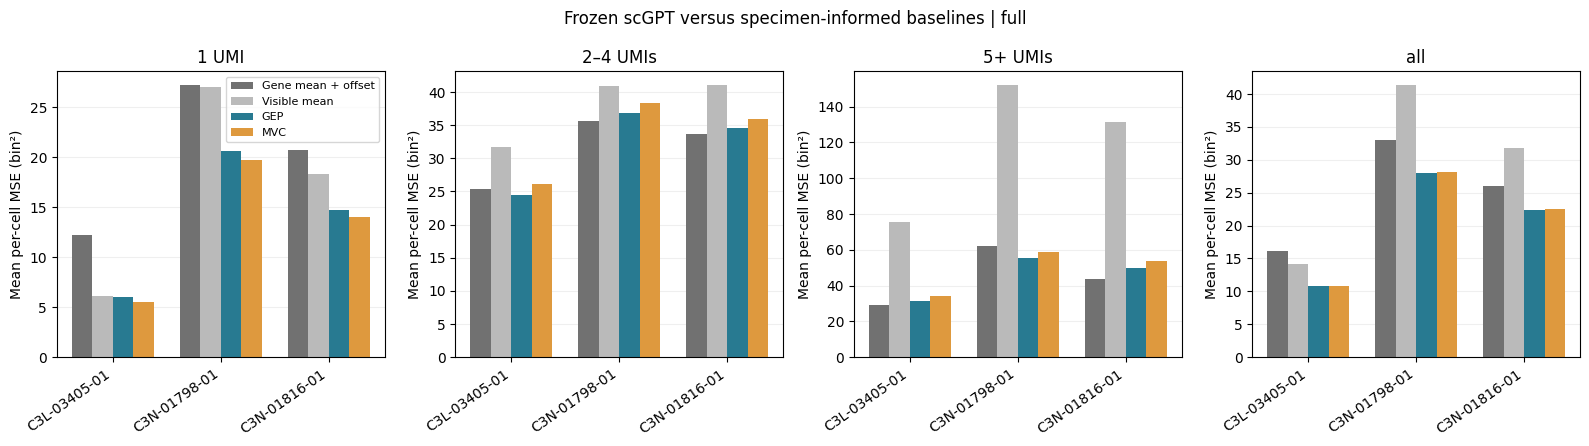

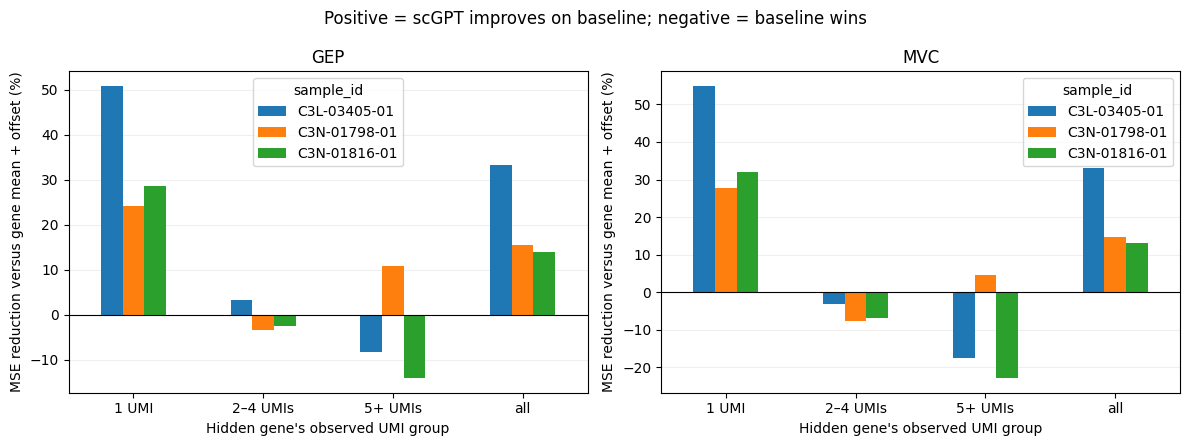

Figures: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/figures


In [19]:
# 8 — Two compact report figures: native-bin loss and advantage over the strong baseline.
import matplotlib.pyplot as plt

figure_dir = RUN_DIR / "figures"
figure_dir.mkdir(exist_ok=True)
sample_order = list(dict.fromkeys(all_summary["sample_id"]))
methods = ["gene_mean_plus_offset", "visible_mean", "GEP", "MVC"]
colors = ["#717171", "#BABABA", "#287A91", "#DE993E"]
labels = ["Gene mean + offset", "Visible mean", "GEP", "MVC"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), squeeze=False)
for ax, group in zip(axes[0], COUNT_GROUPS):
    table = all_summary.loc[all_summary["count_group"].eq(group)].pivot(
        index="sample_id", columns="method", values="mean_MSE").reindex(index=sample_order, columns=methods)
    x = np.arange(len(sample_order))
    width = 0.19
    for k, (method, color, label) in enumerate(zip(methods, colors, labels)):
        ax.bar(x + (k - 1.5) * width, table[method], width, label=label, color=color)
    ax.set_title(group)
    ax.set_xticks(x, sample_order, rotation=35, ha="right")
    ax.set_ylabel("Mean per-cell MSE (bin²)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Frozen scGPT versus specimen-informed baselines | {MODE}")
fig.tight_layout()
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), squeeze=False)
for ax, head in zip(axes[0], ["GEP", "MVC"]):
    table = all_summary.loc[all_summary["method"].eq(head)].pivot(
        index="count_group", columns="sample_id", values="percent_MSE_reduction"
    ).reindex(COUNT_GROUPS)
    table.reindex(columns=sample_order).plot.bar(ax=ax, rot=0)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(head)
    ax.set_xlabel("Hidden gene's observed UMI group")
    ax.set_ylabel("MSE reduction versus gene mean + offset (%)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Positive = scGPT improves on baseline; negative = baseline wins")
fig.tight_layout()
fig.savefig(figure_dir / "relative_gain_by_specimen.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "relative_gain_by_specimen.pdf", bbox_inches="tight")
plt.show()
print("Figures:", figure_dir)


In [20]:
kidney_summary = pd.read_csv(KIDNEY_SUMMARY_FILE)
brain_summary = all_summary.copy()

comparison = pd.concat(
    [
        kidney_summary.assign(tissue="Kidney"),
        brain_summary.assign(tissue="Brain"),
    ],
    ignore_index=True,
)

selected = comparison[
    comparison["method"].isin(["GEP", "MVC"])
].copy()

display(
    selected[
        [
            "tissue",
            "sample_id",
            "count_group",
            "method",
            "n_cells",
            "mean_MSE",
            "mean_MSE_gain",
            "percent_MSE_reduction",
        ]
    ]
    .sort_values(["count_group", "method", "tissue", "sample_id"])
    .round(3)
)

comparison.to_csv(
    RUN_DIR / "kidney_and_brain_comparison.csv",
    index=False,
)

,tissue,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
96,Brain,C3L-03405-01,1 UMI,GEP,128,6.005,6.208,50.833
128,Brain,C3N-01798-01,1 UMI,GEP,128,20.627,6.602,24.247
160,Brain,C3N-01816-01,1 UMI,GEP,128,14.764,5.909,28.582
32,Kidney,C3L-00359-01,1 UMI,GEP,128,8.307,4.777,36.508
64,Kidney,C3L-01287-01,1 UMI,GEP,128,10.018,3.518,25.990
0,Kidney,C3N-00148-01,1 UMI,GEP,128,7.266,2.277,23.863
98,Brain,C3L-03405-01,1 UMI,MVC,128,5.507,6.706,54.909
130,Brain,C3N-01798-01,1 UMI,MVC,128,19.677,7.552,27.736
162,Brain,C3N-01816-01,1 UMI,MVC,128,14.031,6.642,32.128
34,Kidney,C3L-00359-01,1 UMI,MVC,128,8.003,5.081,38.835


In [21]:
from pathlib import Path
import json
import pandas as pd

results_root = Path.home() / "scgpt-cna/multicase_expression/results"

expected = {
    "Kidney": {"C3N-00148-01", "C3L-00359-01", "C3L-01287-01"},
    "Brain": {"C3L-03405-01", "C3N-01798-01", "C3N-01816-01"},
}

def recover_run(sample_ids):
    candidates = []

    for path in results_root.glob("*/all_specimens_summary.csv"):
        manifest_path = path.parent / "run_manifest.json"
        if not manifest_path.exists():
            continue

        manifest = json.loads(manifest_path.read_text())
        if manifest.get("mode") != "full":
            continue
        if manifest.get("mask_seeds") != [42, 43, 44, 45]:
            continue

        table = pd.read_csv(path)
        if not sample_ids.issubset(set(table["sample_id"])):
            continue

        table = table[table["sample_id"].isin(sample_ids)].copy()
        overall = table[
            table["count_group"].eq("all")
            & table["method"].isin(["GEP", "MVC"])
        ]

        if len(overall) != 2 * len(sample_ids):
            continue
        if not overall["n_cells"].eq(128).all():
            continue

        candidates.append((path, table, manifest))

    assert candidates, f"No completed matching full run found for {sample_ids}"
    return max(candidates, key=lambda item: item[0].parent.name)

recovered = {label: recover_run(ids) for label, ids in expected.items()}

# Confirm that the two runs used the same main experimental settings.
protocol_keys = [
    "checkpoint_sha256", "helper_sha256",
    "historical_preprocess_sha256",
    "n_reference", "n_evaluation_reserved",
    "mask_fraction", "mask_seeds",
]
kidney_manifest = recovered["Kidney"][2]
brain_manifest = recovered["Brain"][2]

for key in protocol_keys:
    assert kidney_manifest[key] == brain_manifest[key], (
        f"Protocol differs for {key}; inspect before comparing."
    )
assert kidney_manifest["config"] == brain_manifest["config"]

frames = []
for label, (path, table, _) in recovered.items():
    print(label, "loaded from:", path)
    frames.append(table)

comparison = pd.concat(frames, ignore_index=True)

# Read tissue from metadata, rather than assigning it from a variable name.
sample_metadata = pd.read_csv(META, sep="\t", dtype=str)
assert sample_metadata["sample_id"].is_unique
tissue_lookup = sample_metadata.set_index("sample_id")["primary_site"]

comparison["tissue"] = comparison["sample_id"].map(tissue_lookup)
assert comparison["tissue"].notna().all()
assert not comparison.duplicated(
    ["sample_id", "count_group", "method"]
).any()

display(
    comparison[
        comparison["method"].isin(["GEP", "MVC"])
        & comparison["count_group"].eq("5+ UMIs")
    ][[
        "tissue", "sample_id", "method", "n_cells",
        "mean_MSE", "mean_MSE_gain", "percent_MSE_reduction"
    ]].sort_values(["tissue", "sample_id", "method"]).round(3)
)

Kidney loaded from: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/all_specimens_summary.csv
Brain loaded from: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/all_specimens_summary.csv


,tissue,sample_id,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
112,Brain,C3L-03405-01,GEP,127,31.525,-2.386,-8.187
114,Brain,C3L-03405-01,MVC,127,34.251,-5.111,-17.540
144,Brain,C3N-01798-01,GEP,128,55.243,6.651,10.746
146,Brain,C3N-01798-01,MVC,128,59.003,2.891,4.671
176,Brain,C3N-01816-01,GEP,128,49.966,-6.166,-14.077
178,Brain,C3N-01816-01,MVC,128,53.801,-10.001,-22.832
48,Kidney,C3L-00359-01,GEP,128,40.734,-12.545,-44.502
50,Kidney,C3L-00359-01,MVC,128,43.080,-14.891,-52.825
80,Kidney,C3L-01287-01,GEP,128,44.241,-0.184,-0.418
82,Kidney,C3L-01287-01,MVC,128,48.263,-4.205,-9.545


### 3. Why is scGPT better on singletons?

In [22]:
# 1 — Configuration. This cell is independent of the inference notebook's RUN_DIR.
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
RESULTS_ROOT = ROOT / "multicase_expression/results"
META = Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale/metadata/sample_md.tsv")
SAMPLE_IDS = [
    "C3N-00148-01", "C3L-00359-01", "C3L-01287-01",
    "C3L-03405-01", "C3N-01798-01", "C3N-01816-01",
]
EXPECTED_MASK_SEEDS = [42, 43, 44, 45]
EXPECTED_N_CELLS = 128
# Optional: explicitly select the timestamped RUN directory for any specimen.
# Otherwise choose its most recent completed compatible full run and print it.
RUN_OVERRIDES = {}  # {"C3N-00148-01": Path("/home/akash1/scgpt-cna/multicase_expression/results/..._full")}

COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]
BASELINE_COLUMN = "gene_mean_plus_offset"
SOURCE_METHODS = {
    "Baseline": BASELINE_COLUMN,
    "GEP": "GEP", "MVC": "MVC",
    "GEP_shuffled": "GEP_shuffled", "MVC_shuffled": "MVC_shuffled",
}
N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 20261106
N_FOLDS = 4
CALIBRATION_SEED = 20261106

OUT = ROOT / "expression_diagnostics" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT.mkdir(parents=True, exist_ok=False)
FIGURES = OUT / "figures"
FIGURES.mkdir()
print("Python:", sys.executable)
print("Reading:", RESULTS_ROOT)
print("Writing new diagnostics:", OUT)
assert RESULTS_ROOT.is_dir() and META.is_file()
assert len(SAMPLE_IDS) == len(set(SAMPLE_IDS))


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
Reading: /home/akash1/scgpt-cna/multicase_expression/results
Writing new diagnostics: /home/akash1/scgpt-cna/expression_diagnostics/20261107T203907903086Z


In [23]:
# 2 — Recover source files by specimen ID; tissue comes from metadata, not a manual label.
sample_md = pd.read_csv(META, sep="\t", dtype=str)
assert sample_md["sample_id"].is_unique
sample_md = sample_md.set_index("sample_id")
assert set(SAMPLE_IDS).issubset(sample_md.index)

def protocol_signature(manifest):
    keys = ["checkpoint_sha256", "helper_sha256", "historical_preprocess_sha256",
            "historical_collator_sha256", "vocab_sha256", "n_reference",
            "n_evaluation_reserved", "mask_fraction", "mask_seeds", "config"]
    return json.dumps({k: manifest[k] for k in keys}, sort_keys=True)

def locate_source(sid):
    if sid in RUN_OVERRIDES:
        paths = [Path(RUN_OVERRIDES[sid]) / sid / "summary_by_count_group.csv"]
    else:
        paths = list(RESULTS_ROOT.glob(f"*/{sid}/summary_by_count_group.csv"))
    candidates = []
    for summary_path in paths:
        sample_dir = summary_path.parent
        run_dir = sample_dir.parent
        manifest_path = run_dir / "run_manifest.json"
        if not summary_path.is_file() or not manifest_path.is_file():
            continue
        manifest = json.loads(manifest_path.read_text())
        if manifest.get("mode") != "full" or manifest.get("mask_seeds") != EXPECTED_MASK_SEEDS:
            continue
        if manifest.get("n_evaluated") != EXPECTED_N_CELLS or not manifest.get("run_shuffled"):
            continue
        needed = [sample_dir / f"query_predictions_mask{s}.csv.gz" for s in EXPECTED_MASK_SEEDS]
        needed += [sample_dir / "cell_metadata_and_splits.tsv"]
        if not all(p.is_file() for p in needed):
            continue
        summary = pd.read_csv(summary_path)
        check = summary[summary["count_group"].eq("all") & summary["method"].isin(["GEP", "MVC"])]
        if len(check) != 2 or set(check["sample_id"]) != {sid} or not check["n_cells"].eq(EXPECTED_N_CELLS).all():
            continue
        candidates.append((run_dir, sample_dir, manifest, summary))
    assert candidates, (
        f"No completed compatible full run with query files found for {sid}. "
        "Check RUN_OVERRIDES and that SAVE_QUERY_PREDICTIONS was enabled. "
        "This diagnostic never launches inference automatically."
    )
    return max(candidates, key=lambda item: item[0].name)

sources = {sid: locate_source(sid) for sid in SAMPLE_IDS}
assert len({protocol_signature(v[2]) for v in sources.values()}) == 1, (
    "Selected runs have different protocols. Use RUN_OVERRIDES to select matching runs."
)
source_rows, query_parts, obs_parts, source_summaries = [], [], [], []
for sid in SAMPLE_IDS:
    run_dir, sample_dir, manifest, summary = sources[sid]
    obs = pd.read_csv(sample_dir / "cell_metadata_and_splits.tsv", sep="\t", dtype={"cell_id": str})
    assert obs["cell_id"].is_unique
    reference_ids = set(obs.loc[obs["split"].eq("reference"), "cell_id"])
    evaluation_ids = set(obs.loc[obs["split"].eq("evaluation_reserved"), "cell_id"])
    assert len(reference_ids) == manifest["n_reference"]
    assert len(evaluation_ids) == EXPECTED_N_CELLS and reference_ids.isdisjoint(evaluation_ids)
    obs_parts.append(obs)
    source_summaries.append(summary)
    for seed in EXPECTED_MASK_SEEDS:
        path = sample_dir / f"query_predictions_mask{seed}.csv.gz"
        frame = pd.read_csv(path)
        required = {"sample_id", "case_id", "cell_id", "cell_index", "mask_seed",
                    "gene_token", "original_umi", "target_bin", "reference_support"}
        required.update(SOURCE_METHODS.values())
        assert required.issubset(frame.columns), f"Missing columns in {path}: {required-set(frame.columns)}"
        assert set(frame["sample_id"]) == {sid} and set(frame["mask_seed"]) == {seed}
        assert set(frame["cell_id"]) == evaluation_ids
        assert set(frame["case_id"]) == {sample_md.loc[sid, "case_id"]}
        assert frame["cell_id"].str.startswith(sid + ":").all()
        assert not frame.duplicated(["cell_id", "mask_seed", "gene_token"]).any()
        assert frame["target_bin"].between(1, 50).all()
        assert (frame["original_umi"] > 0).all()
        assert np.equal(frame["original_umi"], np.rint(frame["original_umi"])).all()
        assert np.isfinite(frame[["target_bin", *SOURCE_METHODS.values()]].to_numpy()).all()
        frame["tissue"] = sample_md.loc[sid, "primary_site"]
        frame["diagnosis"] = sample_md.loc[sid, "diagnoses.0.primary_diagnosis"]
        frame["count_group"] = np.select(
            [frame["original_umi"].eq(1), frame["original_umi"].le(4)],
            COUNT_GROUPS[:2], default=COUNT_GROUPS[2])
        query_parts.append(frame)
    source_rows.append({"sample_id": sid, "case_id": sample_md.loc[sid, "case_id"],
                        "tissue": sample_md.loc[sid, "primary_site"],
                        "diagnosis": sample_md.loc[sid, "diagnoses.0.primary_diagnosis"],
                        "source_run": str(run_dir), "sample_directory": str(sample_dir),
                        "n_cells": len(evaluation_ids), "n_masks": len(EXPECTED_MASK_SEEDS)})

queries = pd.concat(query_parts, ignore_index=True)
cell_metadata = pd.concat(obs_parts, ignore_index=True)
saved_summary = pd.concat(source_summaries, ignore_index=True)
source_table = pd.DataFrame(source_rows)
source_table.to_csv(OUT / "source_runs.csv", index=False)
sample_info = source_table.set_index("sample_id")[["case_id", "tissue", "diagnosis"]]
assert not queries.duplicated(["sample_id", "cell_id", "mask_seed", "gene_token"]).any()
assert queries.groupby("cell_id")["mask_seed"].nunique().eq(len(EXPECTED_MASK_SEEDS)).all()
del query_parts, obs_parts
display(source_table)
print(f"Loaded {len(queries):,} query events from {queries['cell_id'].nunique()} cells.")
print("Repeated queries/masks within cells are not independent patients.")


,sample_id,case_id,tissue,diagnosis,source_run,sample_directory,n_cells,n_masks
0,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",/home/akash1/scgpt-cna/multicase_expression/re...,/home/akash1/scgpt-cna/multicase_expression/re...,128,4
1,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",/home/akash1/scgpt-cna/multicase_expression/re...,/home/akash1/scgpt-cna/multicase_expression/re...,128,4
2,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",/home/akash1/scgpt-cna/multicase_expression/re...,/home/akash1/scgpt-cna/multicase_expression/re...,128,4
3,C3L-03405-01,C3L-03405,Brain,Glioblastoma,/home/akash1/scgpt-cna/multicase_expression/re...,/home/akash1/scgpt-cna/multicase_expression/re...,128,4
4,C3N-01798-01,C3N-01798,Brain,Glioblastoma,/home/akash1/scgpt-cna/multicase_expression/re...,/home/akash1/scgpt-cna/multicase_expression/re...,128,4
5,C3N-01816-01,C3N-01816,Brain,Glioblastoma,/home/akash1/scgpt-cna/multicase_expression/re...,/home/akash1/scgpt-cna/multicase_expression/re...,128,4


Loaded 851,356 query events from 768 cells.
Repeated queries/masks within cells are not independent patients.


In [24]:
# 3 — Exact within-cell/mask decomposition; macro-average masks before cells.
def score_wide(frame, methods):
    rows = []
    for (sid, cell_id, seed), part in frame.groupby(["sample_id", "cell_id", "mask_seed"], sort=False):
        y_all = part["target_bin"].to_numpy(dtype=float)
        labels = part["count_group"].to_numpy()
        raw_umi = part["original_umi"].to_numpy(dtype=float)
        predictions = {name: part[col].to_numpy(dtype=float) for name, col in methods.items()}
        for group in COUNT_GROUPS:
            keep = np.ones(len(part), dtype=bool) if group == "all" else labels == group
            n = int(keep.sum())
            if n == 0:
                continue
            y = y_all[keep]
            yc = y - y.mean()
            for method, values in predictions.items():
                p = values[keep]
                error = p - y
                bias = float(error.mean())
                mse = float(np.mean(error**2))
                centered = float(np.mean((error - bias)**2))
                np.testing.assert_allclose(mse, bias**2 + centered, atol=1e-9)
                rows.append({
                    "sample_id": sid, "cell_id": cell_id, "mask_seed": seed,
                    "count_group": group, "method": method, "n_queries": n,
                    "MSE": mse, "MAE": float(np.abs(error).mean()),
                    "mean_error": bias, "squared_bias": bias**2, "centered_MSE": centered,
                    "target_mean": float(y.mean()), "prediction_mean": float(p.mean()),
                    "target_variance": float(np.mean(yc**2)),
                    "prediction_variance": float(np.mean((p-p.mean())**2)),
                    "prediction_target_covariance": float(np.mean((p-p.mean()) * yc)),
                    "target_std": float(y.std()), "prediction_std": float(p.std()),
                    "mean_umi": float(raw_umi[keep].mean()),
                })
    return pd.DataFrame(rows)

SCORE_COLUMNS = ["MSE", "MAE", "mean_error", "squared_bias", "centered_MSE",
                 "target_mean", "prediction_mean", "target_variance", "prediction_variance",
                 "prediction_target_covariance", "target_std", "prediction_std", "mean_umi"]

def average_masks(scores):
    keys = ["sample_id", "cell_id", "count_group", "method"]
    averaged = scores.groupby(keys, as_index=False)[SCORE_COLUMNS].mean()
    coverage = scores.groupby(keys, as_index=False).agg(
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
        single_query_masks=("n_queries", lambda s: int(s.eq(1).sum())))
    return averaged.merge(coverage, on=keys, validate="one_to_one")

def add_baseline_gains(per_cell):
    base = per_cell.loc[per_cell["method"].eq("Baseline"),
                       ["sample_id", "cell_id", "count_group", "MSE", "squared_bias", "centered_MSE"]]
    base = base.rename(columns={"MSE": "baseline_MSE", "squared_bias": "baseline_squared_bias",
                                "centered_MSE": "baseline_centered_MSE"})
    result = per_cell.merge(base, on=["sample_id", "cell_id", "count_group"], validate="many_to_one")
    result["MSE_gain"] = result["baseline_MSE"] - result["MSE"]
    result["bias_component_gain"] = result["baseline_squared_bias"] - result["squared_bias"]
    result["centered_component_gain"] = result["baseline_centered_MSE"] - result["centered_MSE"]
    np.testing.assert_allclose(result["MSE_gain"], result["bias_component_gain"] +
                               result["centered_component_gain"], atol=1e-8)
    return result

def summarize_cells(per_cell):
    summary = per_cell.groupby(["sample_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"), mean_MAE=("MAE", "mean"),
        mean_signed_error=("mean_error", "mean"), mean_squared_bias=("squared_bias", "mean"),
        mean_centered_MSE=("centered_MSE", "mean"),
        mean_target_std=("target_std", "mean"), mean_prediction_std=("prediction_std", "mean"),
        mean_baseline_MSE=("baseline_MSE", "mean"), mean_MSE_gain=("MSE_gain", "mean"),
        bias_component_gain=("bias_component_gain", "mean"),
        centered_component_gain=("centered_component_gain", "mean"),
        cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
        query_events=("query_events", "sum"), single_query_masks=("single_query_masks", "sum"),
    )
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    summary["percent_cells_beating_baseline"] = 100 * summary["cells_beating_baseline"] / summary["n_cells"]
    return summary.merge(sample_info.reset_index(), on="sample_id", validate="many_to_one")

def bootstrap_mean(values, seed=BOOTSTRAP_SEED):
    values = np.asarray(values, dtype=float)
    assert len(values) and np.isfinite(values).all()
    rng = np.random.default_rng(seed)
    means = values[rng.integers(0, len(values), size=(N_BOOTSTRAP, len(values)))].mean(axis=1)
    return np.quantile(means, [0.025, 0.975])


In [25]:
# 4 — Diagnostic 1: signed error, squared bias and remaining error.
scores_by_mask = score_wide(queries, SOURCE_METHODS)
cell_scores = add_baseline_gains(average_masks(scores_by_mask))
decomposition = summarize_cells(cell_scores)

# Confirm we reconstructed the original scores before doing new analysis.
check = decomposition.copy()
check["source_method"] = check["method"].map(SOURCE_METHODS)
check = check.merge(saved_summary[["sample_id", "count_group", "method", "mean_MSE"]].rename(
    columns={"method": "source_method", "mean_MSE": "saved_MSE"}),
    on=["sample_id", "count_group", "source_method"], validate="one_to_one")
assert len(check) == len(decomposition)
np.testing.assert_allclose(check["mean_MSE"], check["saved_MSE"], rtol=1e-5, atol=1e-5)
print("Reconstructed MSE matches the saved benchmark for every selected method/group.")

display(decomposition.loc[decomposition["method"].isin(["Baseline", "GEP", "MVC"]), [
    "tissue", "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_signed_error", "mean_squared_bias", "mean_centered_MSE",
    "mean_target_std", "mean_prediction_std", "mean_MSE_gain",
]].round(3))

# Oracle comparison excludes cell/mask/groups containing only one query. Centering
# a single error makes it zero by construction and is not useful evidence.
oracle_scores = scores_by_mask.loc[scores_by_mask["n_queries"].ge(2)]
oracle_cells = add_baseline_gains(average_masks(oracle_scores))
oracle_summary = summarize_cells(oracle_cells)
print("Oracle centering: eligible masks have >=2 queries in the group. Not deployable calibration.")
display(oracle_summary.loc[oracle_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE_gain",
    "bias_component_gain", "centered_component_gain",
]].round(3))

# Coverage: queried_pairs counts repeated events; unique_cell_gene_pairs removes
# repeated masks for the same cell/gene, but neither is a patient sample size.
coverage_parts = []
for group in COUNT_GROUPS:
    part = queries if group == "all" else queries.loc[queries["count_group"].eq(group)]
    coverage = part.groupby("sample_id", as_index=False).agg(
        n_cells=("cell_id", "nunique"), query_events=("gene_token", "size"))
    distinct = part.drop_duplicates(["sample_id", "cell_id", "gene_token"]).groupby("sample_id").size()
    coverage["unique_cell_gene_pairs"] = coverage["sample_id"].map(distinct)
    coverage["count_group"] = group
    coverage_parts.append(coverage)
coverage = pd.concat(coverage_parts, ignore_index=True)
display(coverage)

scores_by_mask.to_csv(OUT / "errors_by_cell_mask_group.csv.gz", index=False)
cell_scores.to_csv(OUT / "errors_by_cell.csv", index=False)
decomposition.to_csv(OUT / "error_decomposition.csv", index=False)
oracle_summary.to_csv(OUT / "oracle_centering_diagnostic.csv", index=False)
coverage.to_csv(OUT / "query_coverage.csv", index=False)


Reconstructed MSE matches the saved benchmark for every selected method/group.


,tissue,sample_id,count_group,method,n_cells,mean_MSE,mean_signed_error,mean_squared_bias,mean_centered_MSE,mean_target_std,mean_prediction_std,mean_MSE_gain
0,Kidney,C3L-00359-01,1 UMI,Baseline,128,13.084,1.804,4.755,8.330,0.000,2.869,0.000
1,Kidney,C3L-00359-01,1 UMI,GEP,128,8.307,2.131,5.388,2.919,0.000,1.559,4.777
3,Kidney,C3L-00359-01,1 UMI,MVC,128,8.003,2.037,5.102,2.901,0.000,1.566,5.081
5,Kidney,C3L-00359-01,2–4 UMIs,Baseline,128,30.192,-4.267,19.891,10.302,1.386,3.217,0.000
6,Kidney,C3L-00359-01,2–4 UMIs,GEP,128,30.540,-4.950,25.084,5.456,1.386,2.112,-0.348
...,...,...,...,...,...,...,...,...,...,...,...,...
111,Brain,C3N-01816-01,5+ UMIs,GEP,128,49.966,-6.106,40.297,9.669,0.674,3.178,-6.166
113,Brain,C3N-01816-01,5+ UMIs,MVC,128,53.801,-6.517,44.999,8.802,0.674,3.008,-10.001
115,Brain,C3N-01816-01,all,Baseline,128,26.016,0.005,0.112,25.904,5.409,3.882,0.000
116,Brain,C3N-01816-01,all,GEP,128,22.381,-0.009,0.086,22.294,5.409,2.907,3.635


Oracle centering: eligible masks have >=2 queries in the group. Not deployable calibration.


,sample_id,count_group,method,n_cells,mean_MSE_gain,bias_component_gain,centered_component_gain
1,C3L-00359-01,1 UMI,GEP,128,4.777,-0.633,5.410
3,C3L-00359-01,1 UMI,MVC,128,5.081,-0.347,5.428
6,C3L-00359-01,2–4 UMIs,GEP,128,-0.348,-5.194,4.846
8,C3L-00359-01,2–4 UMIs,MVC,128,-1.297,-6.471,5.174
11,C3L-00359-01,5+ UMIs,GEP,127,-12.204,-11.454,-0.750
13,C3L-00359-01,5+ UMIs,MVC,127,-14.666,-14.869,0.203
16,C3L-00359-01,all,GEP,128,3.101,0.024,3.077
18,C3L-00359-01,all,MVC,128,3.031,0.039,2.992
21,C3L-01287-01,1 UMI,GEP,128,3.518,0.829,2.689
23,C3L-01287-01,1 UMI,MVC,128,3.942,1.305,2.637


,sample_id,n_cells,query_events,unique_cell_gene_pairs,count_group
0,C3L-00359-01,128,99252,76789,1 UMI
1,C3L-01287-01,128,99507,76795,1 UMI
2,C3L-03405-01,128,95590,70015,1 UMI
3,C3N-00148-01,128,105289,80319,1 UMI
4,C3N-01798-01,128,94074,77898,1 UMI
5,C3N-01816-01,128,99927,82252,1 UMI
6,C3L-00359-01,128,32637,25854,2–4 UMIs
7,C3L-01287-01,128,34861,27674,2–4 UMIs
8,C3L-03405-01,128,26258,19865,2–4 UMIs
9,C3N-00148-01,128,33768,26155,2–4 UMIs


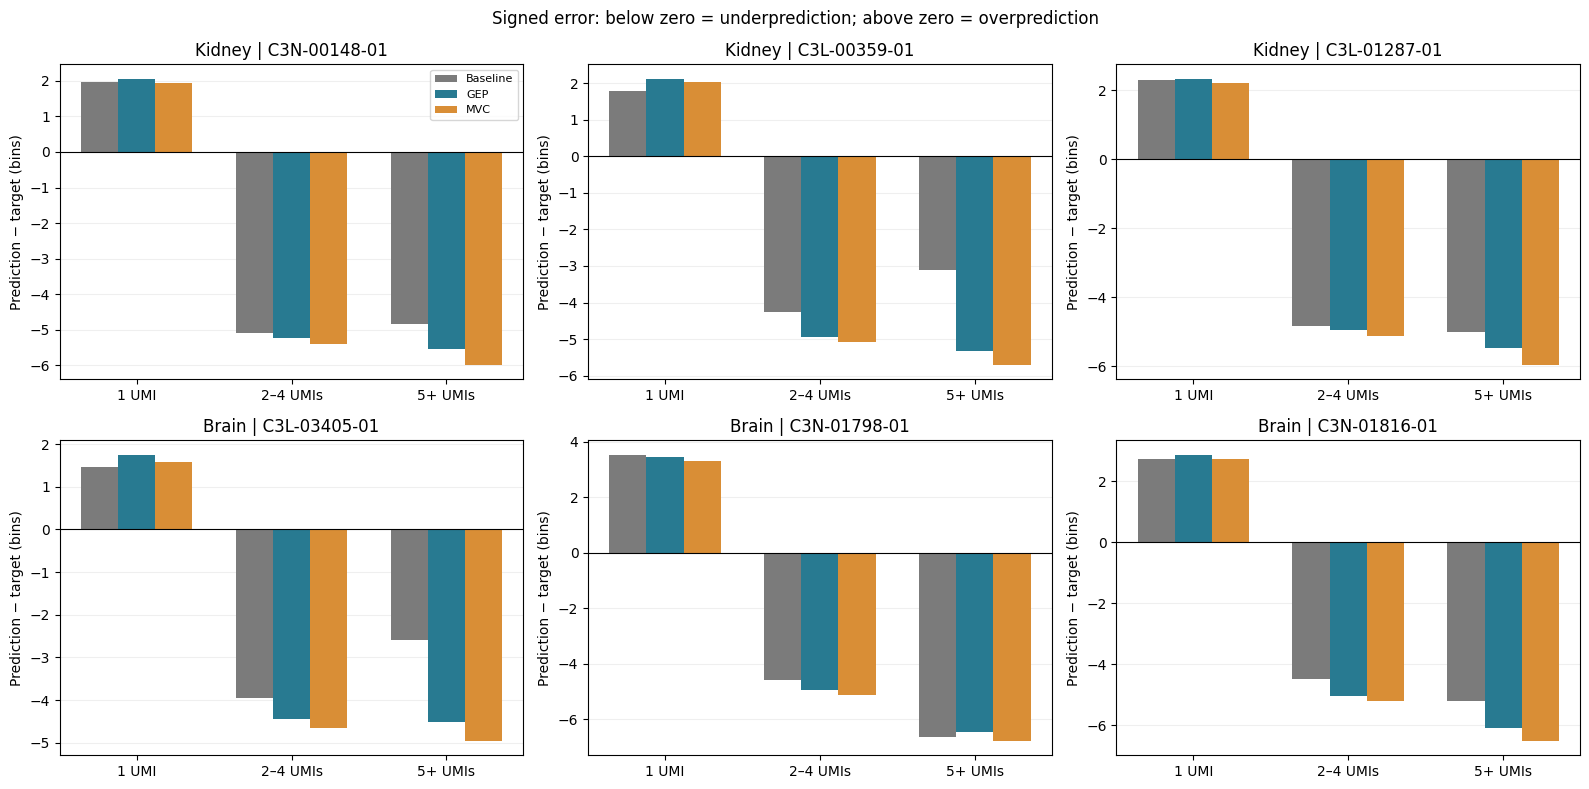

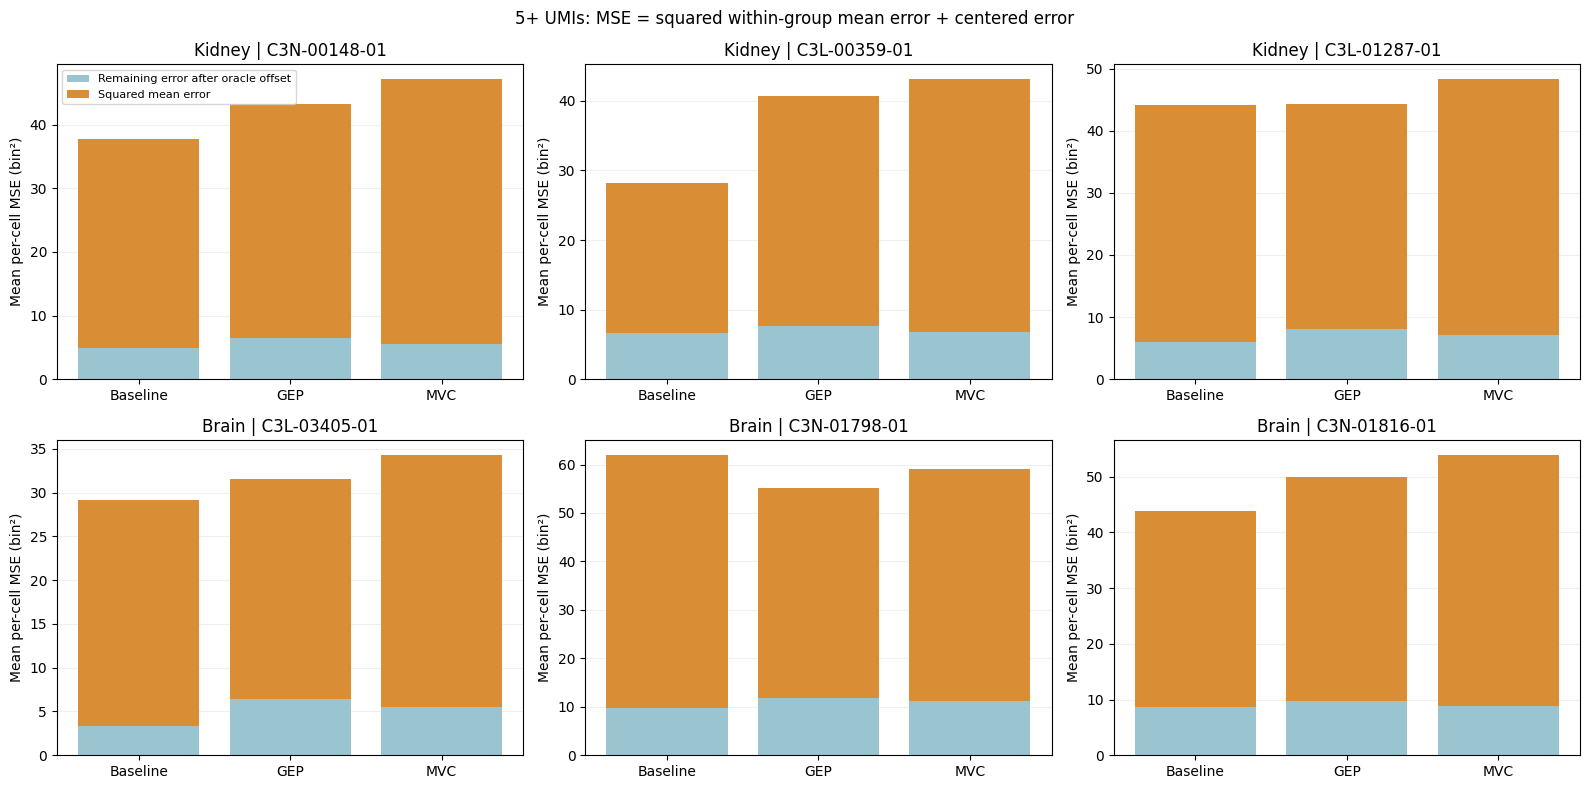

Interpretation:
• The stacked decomposition uses each cell/mask/group's mean error, not one pooled offset.
• Tall orange bars suggest a common within-group shift; blue includes noise and other errors.
• A smaller prediction std alone is not proof of a defect: MSE-optimal means can be less variable.
• Singleton targets are identical within a cell: low singleton error is not evidence of ranking singleton genes.


In [26]:
# 5 — Diagnostic 1 figures: signs and MSE components, in bin units.
methods = ["Baseline", "GEP", "MVC"]
colors = ["#7B7B7B", "#287A91", "#D98E36"]
groups_to_plot = COUNT_GROUPS[:3]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), squeeze=False)
for ax, sid in zip(axes.flat, SAMPLE_IDS):
    part = decomposition.loc[decomposition["sample_id"].eq(sid)]
    x = np.arange(3)
    for j, (method, color) in enumerate(zip(methods, colors)):
        means = part.loc[part["method"].eq(method)].set_index("count_group")["mean_signed_error"]
        ax.bar(x + (j-1)*.24, means.reindex(groups_to_plot), .24, color=color, label=method)
    ax.axhline(0, color="black", linewidth=.8)
    ax.set_xticks(x, groups_to_plot)
    ax.set_ylabel("Prediction − target (bins)")
    ax.set_title(f"{sample_info.loc[sid, 'tissue']} | {sid}")
    ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Signed error: below zero = underprediction; above zero = overprediction")
fig.tight_layout()
fig.savefig(FIGURES / "signed_error_by_count_group.png", dpi=200, bbox_inches="tight")
fig.savefig(FIGURES / "signed_error_by_count_group.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8), squeeze=False)
for ax, sid in zip(axes.flat, SAMPLE_IDS):
    part = decomposition.loc[decomposition["sample_id"].eq(sid) &
                             decomposition["count_group"].eq("5+ UMIs")].set_index("method").reindex(methods)
    bias = part["mean_squared_bias"].to_numpy()
    remaining = part["mean_centered_MSE"].to_numpy()
    ax.bar(methods, remaining, color="#9AC5D0", label="Remaining error after oracle offset")
    ax.bar(methods, bias, bottom=remaining, color="#D98E36", label="Squared mean error")
    ax.set_ylabel("Mean per-cell MSE (bin²)")
    ax.set_title(f"{sample_info.loc[sid, 'tissue']} | {sid}")
    ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
axes.flat[0].legend(fontsize=8)
fig.suptitle("5+ UMIs: MSE = squared within-group mean error + centered error")
fig.tight_layout()
fig.savefig(FIGURES / "higher_count_mse_components.png", dpi=200, bbox_inches="tight")
fig.savefig(FIGURES / "higher_count_mse_components.pdf", bbox_inches="tight")
plt.show()

print("Interpretation:")
print("• The stacked decomposition uses each cell/mask/group's mean error, not one pooled offset.")
print("• Tall orange bars suggest a common within-group shift; blue includes noise and other errors.")
print("• A smaller prediction std alone is not proof of a defect: MSE-optimal means can be less variable.")
print("• Singleton targets are identical within a cell: low singleton error is not evidence of ranking singleton genes.")


Positive gain means correct gene–expression associations helped.


,sample_id,count_group,head,n_cells,correct_MSE,shuffled_MSE,mean_context_gain,median_context_gain,percent_cells_correct_context_wins,cell_bootstrap_low,cell_bootstrap_high,case_id,tissue,diagnosis
4,C3N-00148-01,5+ UMIs,GEP,127,43.295,55.164,11.869,8.853,90.551,9.801,14.084,C3N-00148,Kidney,"Renal cell carcinoma, NOS"
5,C3N-00148-01,5+ UMIs,MVC,127,47.093,59.609,12.516,10.946,92.913,10.677,14.492,C3N-00148,Kidney,"Renal cell carcinoma, NOS"
12,C3L-00359-01,5+ UMIs,GEP,128,40.734,54.389,13.655,10.475,91.406,11.264,16.116,C3L-00359,Kidney,"Renal cell carcinoma, NOS"
13,C3L-00359-01,5+ UMIs,MVC,128,43.080,60.847,17.766,13.782,96.875,15.057,20.544,C3L-00359,Kidney,"Renal cell carcinoma, NOS"
20,C3L-01287-01,5+ UMIs,GEP,128,44.241,61.614,17.373,11.106,95.312,14.454,20.392,C3L-01287,Kidney,"Renal cell carcinoma, NOS"
21,C3L-01287-01,5+ UMIs,MVC,128,48.263,66.948,18.685,14.672,98.438,15.886,21.516,C3L-01287,Kidney,"Renal cell carcinoma, NOS"
28,C3L-03405-01,5+ UMIs,GEP,127,31.525,40.114,8.588,3.733,71.654,6.483,10.791,C3L-03405,Brain,Glioblastoma
29,C3L-03405-01,5+ UMIs,MVC,127,34.251,42.874,8.623,4.131,70.079,6.603,10.751,C3L-03405,Brain,Glioblastoma
36,C3N-01798-01,5+ UMIs,GEP,128,55.243,91.411,36.168,34.268,99.219,32.356,40.013,C3N-01798,Brain,Glioblastoma
37,C3N-01798-01,5+ UMIs,MVC,128,59.003,95.302,36.299,32.408,99.219,32.462,40.262,C3N-01798,Brain,Glioblastoma


Does the exceptional specimen improve in many cells, or a minority with large gains?


,sample_id,count_group,head,n_cells,mean_gain,median_gain,percent_cells_model_wins,gain_p10,gain_p90,cell_bootstrap_low,cell_bootstrap_high
4,C3L-00359-01,5+ UMIs,GEP,128,-12.545,-16.239,31.250,-35.044,13.296,-15.686,-9.243
5,C3L-00359-01,5+ UMIs,MVC,128,-14.891,-17.666,26.562,-35.244,8.446,-17.900,-11.805
12,C3L-01287-01,5+ UMIs,GEP,128,-0.184,-0.221,50.000,-31.050,33.719,-4.608,4.601
13,C3L-01287-01,5+ UMIs,MVC,128,-4.205,-3.279,46.094,-32.970,28.287,-8.437,0.273
20,C3L-03405-01,5+ UMIs,GEP,127,-2.386,-5.393,35.433,-23.311,18.504,-5.697,0.943
21,C3L-03405-01,5+ UMIs,MVC,127,-5.111,-7.794,32.283,-26.267,17.761,-8.398,-1.806
28,C3N-00148-01,5+ UMIs,GEP,127,-5.595,-11.650,40.157,-33.760,33.995,-10.072,-1.031
29,C3N-00148-01,5+ UMIs,MVC,127,-9.393,-13.806,35.433,-37.998,27.746,-13.648,-4.963
36,C3N-01798-01,5+ UMIs,GEP,128,6.651,0.543,50.000,-19.514,40.504,2.376,10.917
37,C3N-01798-01,5+ UMIs,MVC,128,2.891,-1.312,46.875,-21.682,36.726,-1.266,7.019


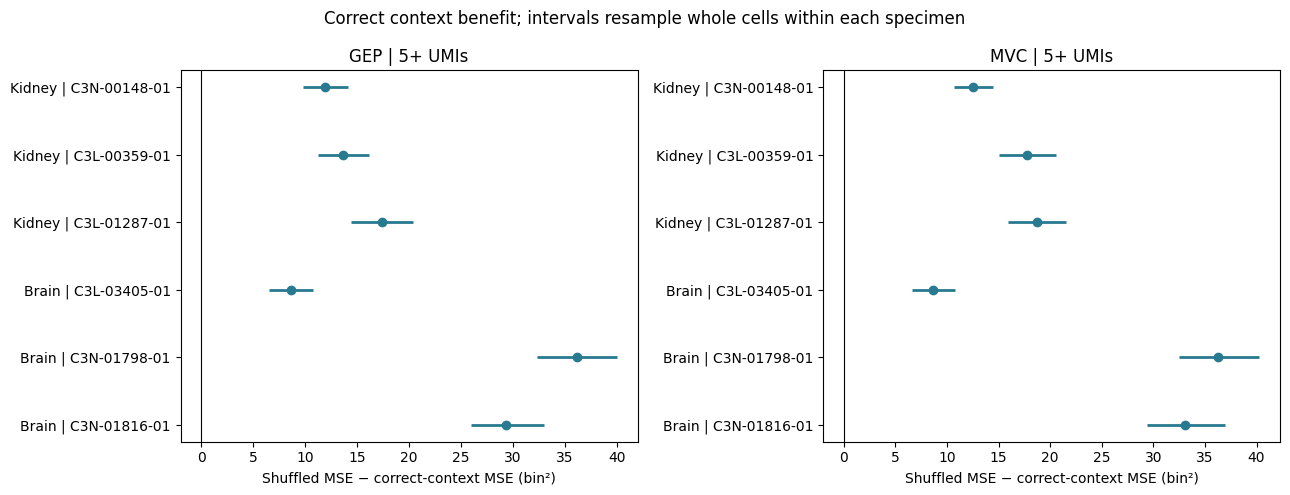

Intervals are conditional cell-resampling summaries. They do not establish population-level
significance across patients and do not account for every dependency between cells/clones.


In [27]:
# 6 — Diagnostic 2: correct versus shuffled context, paired within the same cell.
context_rows = []
for sid in SAMPLE_IDS:
    for group in COUNT_GROUPS:
        part = cell_scores.loc[cell_scores["sample_id"].eq(sid) & cell_scores["count_group"].eq(group)]
        table = part.pivot(index="cell_id", columns="method", values="MSE")
        for head in ["GEP", "MVC"]:
            if table.empty:
                continue
            gain = table[head + "_shuffled"] - table[head]
            lo, hi = bootstrap_mean(gain)
            context_rows.append({
                "sample_id": sid, "count_group": group, "head": head, "n_cells": len(gain),
                "correct_MSE": float(table[head].mean()),
                "shuffled_MSE": float(table[head + "_shuffled"].mean()),
                "mean_context_gain": float(gain.mean()), "median_context_gain": float(gain.median()),
                "percent_cells_correct_context_wins": float(100 * gain.gt(0).mean()),
                "cell_bootstrap_low": float(lo), "cell_bootstrap_high": float(hi),
            })
context_summary = pd.DataFrame(context_rows).merge(sample_info.reset_index(), on="sample_id")
context_summary.to_csv(OUT / "correct_vs_shuffled_context.csv", index=False)
print("Positive gain means correct gene–expression associations helped.")
display(context_summary.loc[context_summary["count_group"].eq("5+ UMIs")].round(3))

# Original model versus baseline: paired per-cell gains and spread of the benefit.
baseline_rows = []
for (sid, group, head), part in cell_scores.loc[cell_scores["method"].isin(["GEP", "MVC"])].groupby(
        ["sample_id", "count_group", "method"]):
    gain = part["MSE_gain"].to_numpy()
    lo, hi = bootstrap_mean(gain)
    baseline_rows.append({"sample_id": sid, "count_group": group, "head": head,
                          "n_cells": len(gain), "mean_gain": float(gain.mean()),
                          "median_gain": float(np.median(gain)),
                          "percent_cells_model_wins": float(100 * np.mean(gain > 0)),
                          "gain_p10": float(np.quantile(gain, .1)), "gain_p90": float(np.quantile(gain, .9)),
                          "cell_bootstrap_low": float(lo), "cell_bootstrap_high": float(hi)})
baseline_gain_spread = pd.DataFrame(baseline_rows)
baseline_gain_spread.to_csv(OUT / "paired_baseline_gain_spread.csv", index=False)
print("Does the exceptional specimen improve in many cells, or a minority with large gains?")
display(baseline_gain_spread.loc[baseline_gain_spread["count_group"].eq("5+ UMIs")].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), squeeze=False)
for ax, head in zip(axes[0], ["GEP", "MVC"]):
    part = context_summary.loc[context_summary["count_group"].eq("5+ UMIs") &
                               context_summary["head"].eq(head)].set_index("sample_id").reindex(SAMPLE_IDS)
    x = part["mean_context_gain"].to_numpy()
    lo = part["cell_bootstrap_low"].to_numpy()
    hi = part["cell_bootstrap_high"].to_numpy()
    y = np.arange(len(SAMPLE_IDS))
    # Draw intervals directly: bootstrap percentile intervals need not contain the point estimate.
    ax.hlines(y, lo, hi, color="#287A91", linewidth=2)
    ax.scatter(x, y, color="#287A91", zorder=3)
    ax.axvline(0, color="black", linewidth=.8)
    ax.set_yticks(y, [f"{sample_info.loc[s, 'tissue']} | {s}" for s in SAMPLE_IDS])
    ax.invert_yaxis()
    ax.set_xlabel("Shuffled MSE − correct-context MSE (bin²)")
    ax.set_title(head + " | 5+ UMIs")
fig.suptitle("Correct context benefit; intervals resample whole cells within each specimen")
fig.tight_layout()
fig.savefig(FIGURES / "higher_count_context_benefit.png", dpi=200, bbox_inches="tight")
fig.savefig(FIGURES / "higher_count_context_benefit.pdf", bbox_inches="tight")
plt.show()
print("Intervals are conditional cell-resampling summaries. They do not establish population-level")
print("significance across patients and do not account for every dependency between cells/clones.")


### Census data comparison

In [1]:
# 1 — Configure the saved Census cohort and a separate output directory.
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import sys
import time

import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse
import torch
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
DATA = ROOT / "sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"
CENSUS_ANNOTATION = DATA
MODEL = ROOT / "models/whole-human"
HELPER = ROOT / "notebooks/scgpt_session/scgpt_session.py"
HISTORICAL = ROOT / "sanity_check/reference_4068d67/scgpt"
RESULTS_ROOT = ROOT / "census_expression/results"

COHORT_ID = "CENSUS_PROXIMAL_TUBULE_256"
SAMPLE_IDS = [COHORT_ID]
MODE = "full"                 # Optional "pilot": eight cells and one mask.
assert MODE in {"pilot", "full"}
SPLIT_SEED = 42
N_REFERENCE = 128
N_EVALUATION = 128
MASK_FRACTION = 0.25
MASK_SEEDS = [42] if MODE == "pilot" else [42, 43, 44, 45]
MAX_EVALUATED = 8 if MODE == "pilot" else N_EVALUATION
ACTIVE_SAMPLE_IDS = SAMPLE_IDS
RUN_SHUFFLED = True
SAVE_QUERY_PREDICTIONS = True
N_THREADS = 4
torch.set_num_threads(N_THREADS)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
RUN_DIR = RESULTS_ROOT / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
required = [DATA, HELPER, HISTORICAL / "preprocess.py", HISTORICAL / "data_collator.py"]
required += [MODEL / name for name in ["args.json", "vocab.json", "best_model.pt"]]
for path in required:
    assert path.is_file(), f"Required existing file not found: {path}"
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| threads:", torch.get_num_threads())
print("Census file:", DATA)
print("Mode:", MODE, "| output:", RUN_DIR)


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
PyTorch: 2.2.2+cpu | threads: 4
Census file: /home/akash1/scgpt-cna/sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad
Mode: full | output: /home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full


In [6]:
# 2 — Pin the preprocessing binding and load every checkpoint tensor strictly.
def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

session = import_file("multicase_verified_session", HELPER)
historical = import_file("multicase_historical_preprocess", HISTORICAL / "preprocess.py")
historical_collator = import_file(
    "scgpt._multicase_historical_collator", HISTORICAL / "data_collator.py"
)
historical_collator.binning = historical.binning
assert historical_collator.binning is historical.binning
assert historical._digitize.__defaults__ == ("one",), "Unexpected tie rule."

model, loaded_vocab, config = session.load_model(MODEL)
model = model.cpu().eval()
vocab = loaded_vocab.get_stoi()
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
pad_id = vocab[config.get("pad_token", "<pad>")]
cls_id = vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value,
    do_mlm=True, do_binning=True, mlm_probability=MASK_FRACTION,
    mask_value=config.get("mask_value", -1), max_length=config["max_seq_len"],
    sampling=True, keep_first_n_tokens=1, data_style="both",
)
print("Helper:", session.__file__)
print("Historical tie rule:", historical._digitize.__defaults__)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b""):
            digest.update(block)
    return digest.hexdigest()

run_manifest = {
    "run_id": RUN_ID, "mode": MODE, "sample_ids": ACTIVE_SAMPLE_IDS,
    "split_seed": SPLIT_SEED, "n_reference": N_REFERENCE,
    "n_evaluation_reserved": N_EVALUATION, "n_evaluated": MAX_EVALUATED,
    "mask_seeds": MASK_SEEDS, "mask_fraction": MASK_FRACTION,
    "run_shuffled": RUN_SHUFFLED, "config": config,
    "helper_path": str(HELPER), "helper_sha256": sha256(HELPER),
    "checkpoint_sha256": sha256(MODEL / "best_model.pt"),
    "vocab_sha256": sha256(MODEL / "vocab.json"),
    "historical_commit": "4068d67caaac1e28d56964da68e0214817e38428",
    "historical_preprocess_sha256": sha256(HISTORICAL / "preprocess.py"),
    "historical_collator_sha256": sha256(HISTORICAL / "data_collator.py"),
    "census_annotation_path": str(CENSUS_ANNOTATION),
    "versions": {p: importlib.metadata.version(p) for p in
                 ["torch", "scgpt", "anndata", "numpy", "scipy", "pandas"]},
    "python": sys.version, "platform": platform.platform(),
    "baseline_scope": "Separate reference cells within the Census cohort; positive-gene bin means; donors may overlap",
    "qc_policy": "No new biological QC exclusions; require enough detected model genes for >=1 query",
    "limitations": [
        "This previously explored Census cohort is not an unseen-patient final test",
        "Only detected genes are queried; zero measurements are not evaluated",
        "Full-profile quantile boundaries use hidden expression values",
        "Census cell-type/disease annotations are reference metadata, not scGPT predictions",
        "Masks and queried genes are not independent donors; donors can overlap across cell splits",
        "Pinned preprocessing is verified; exact released checkpoint training commit is unconfirmed",
    ],
}
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))

run_manifest.update({
    "data_path": str(DATA), "data_sha256": sha256(DATA),
    "dataset_role": "Census proximal-tubule reference cohort",
    "case_id_semantics": "not_applicable; this file mixes donors",
    "pretraining_membership": "unconfirmed",
})
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Strict load: 163 checkpoint tensors; no omitted tensors.
Helper: /home/akash1/scgpt-cna/notebooks/scgpt_session/scgpt_session.py
Historical tie rule: ('one',)


3960

In [7]:
# 3 — Inspect the saved source, without downloading data or loading the count layer.
preview = ad.read_h5ad(DATA, backed="r")
assert "counts" in preview.layers, "Use the saved raw-count layer, not normalized X."
assert {"feature_id", "feature_name"}.issubset(preview.var.columns)
assert {"soma_joinid", "donor_id", "cell_type", "dataset_id", "assay", "disease"}.issubset(preview.obs.columns)
assert preview.n_obs == 256, f"Expected the original 256-cell cohort; found {preview.n_obs}."
assert preview.obs["soma_joinid"].notna().all() and preview.obs["soma_joinid"].is_unique
assert preview.obs["cell_type"].astype(str).str.contains("proximal", case=False).all()
print("Saved Census cohort:", preview.shape)
display(preview.obs.groupby(["dataset_id", "cell_type", "assay", "disease"], observed=True)
        .size().rename("n_cells").reset_index())
print("Cells per donor:")
display(preview.obs["donor_id"].value_counts(dropna=False))
source_manifest = json.loads(json.dumps(preview.uns.get("source_manifest", {}), default=str))
(RUN_DIR / "census_source_manifest.json").write_text(json.dumps(source_manifest, indent=2))
preview.file.close()
del preview

manifest = pd.DataFrame([{
    "sample_id": COHORT_ID, "case_id": "not_applicable", "primary_site": "Kidney",
    "diagnoses.0.primary_diagnosis": "Census-annotated proximal-tubule reference cohort",
    "wgd_status": "not_available", "source_h5ad": str(DATA),
}])
manifest.to_csv(RUN_DIR / "cohort_manifest.tsv", sep="\t", index=False)


Saved Census cohort: (256, 60664)


,dataset_id,cell_type,assay,disease,n_cells
0,9ea768a2-87ab-46b6-a73d-c4e915f25af3,epithelial cell of proximal tubule,10x 3' v2,normal,256


Cells per donor:


donor_id
TTx       118
VHL        26
RCC3       23
Wilms1     19
RCC2       18
TxK4       18
Wilms3     16
TxK1       13
RCC1        3
TxK2        1
Wilms2      1
Name: count, dtype: int64

In [8]:
# 4 — Sparse Census loader with the same downstream matrix/metadata interface.
def load_census_cohort(record):
    started = time.perf_counter()
    dataset = ad.read_h5ad(DATA)
    assert "counts" in dataset.layers
    raw = sparse.csr_matrix(dataset.layers["counts"])
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == dataset.shape
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected raw integer UMI counts."
    var = pd.DataFrame({
        "gene_id": dataset.var["feature_id"].astype(str).to_numpy(),
        "gene_symbol": dataset.var["feature_name"].astype(str).to_numpy(),
    })
    assert var["gene_id"].is_unique
    var["model_symbol"] = var["gene_symbol"]
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    gene_info = var.loc[keep].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, keep.to_numpy()].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = dataset.obs.copy()
    obs["source_obs_name"] = dataset.obs_names.astype(str)
    obs.index = pd.Index(obs["soma_joinid"].astype(str).to_numpy(), name="barcode")
    # 'barcode' is a schema alias for the Census SOMA identifier, not a recovered 10x barcode.
    assert obs.index.is_unique
    obs["cell_index"] = np.arange(len(obs))
    obs["sample_id"] = COHORT_ID
    obs["case_id"] = "not_applicable"
    obs["cell_id"] = COHORT_ID + ":" + obs.index.astype(str)
    obs["tissue"] = "Kidney"
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["cell_type_source"] = "Census annotation"
    obs["malignant_status"] = "not_assigned"
    obs["sample_wgd_status"] = "not_available"
    obs["copykat_group"] = "not_available"
    obs["seurat_cluster"] = "not_available"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mitochondrial = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = 100 * np.asarray(raw[:, mitochondrial].sum(axis=1)).ravel() / obs["total_counts"].replace(0, np.nan)
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = np.asarray(ones.sum(axis=1)).ravel() / obs["detected_genes"].replace(0, np.nan)
    del ones

    singleton_fraction, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i+1]]
        assert len(counts), "A cell has no detected vocabulary-matched genes."
        bins = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(bins, return_counts=True)
        one = counts == 1
        singleton_fraction.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(bins)))
        singleton_bin.append(float(bins[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = singleton_fraction
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin
    total_counts = float(raw.sum())
    report = {
        "sample_id": COHORT_ID, "case_id": "not_applicable", "tissue": "Kidney",
        "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(matrix.sum()) / total_counts,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total_counts,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": 0,
        "annotation_strategy": "Direct Census feature_name matching; retain first duplicate model symbol",
        "n_donors": int(obs["donor_id"].nunique(dropna=True)),
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    print("Full-cohort count profile:")
    display(obs[["total_counts", "detected_genes", "model_detected_genes", "model_count_fraction",
                 "fraction_count_one", "occupied_bins"]].describe().round(3))
    del raw, dataset
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


In [9]:
# 5 — Independent reference cells, native-bin baselines and verified model inputs.
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]

def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])

def reserve_cells(obs):
    minimum_genes = max(2, int(np.ceil(1 / MASK_FRACTION)))
    eligible = np.flatnonzero(obs["model_detected_genes"].to_numpy() >= minimum_genes)
    assert len(eligible) >= N_REFERENCE + N_EVALUATION, (
        f"Only {len(eligible)} eligible cells; need {N_REFERENCE + N_EVALUATION}. "
        "If reducing the budget, use the same setting for all specimens."
    )
    order = np.random.default_rng(SPLIT_SEED).permutation(eligible)
    reference = order[:N_REFERENCE]
    evaluation = order[N_REFERENCE:N_REFERENCE + N_EVALUATION]
    assert not set(reference) & set(evaluation)
    return reference, evaluation

def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

def make_example(matrix, gene_ids, i):
    row = matrix.getrow(int(i))
    return {
        "genes": torch.tensor(np.concatenate(([cls_id], gene_ids[row.indices])), dtype=torch.long),
        "expressions": torch.tensor(np.concatenate(([pad_value], row.data)), dtype=torch.float32),
    }

def make_batch(matrix, gene_ids, evaluation, seed):
    # Always collate ALL reserved cells, even for an eight-cell pilot. The collator
    # chooses lengths using the batch. Fresh examples avoid in-place double binning.
    old_np = np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            np.random.seed(seed)
            return collator([make_example(matrix, gene_ids, i) for i in evaluation])
    finally:
        np.random.set_state(old_np)

def verified_input(matrix, gene_ids, batch, j, i):
    vm = batch["pcpt_gene"][j].ne(pad_id)
    qm = batch["gen_gene"][j].ne(pad_id)
    known_ids = batch["pcpt_gene"][j, vm]
    known_values = batch["pcpt_expr"][j, vm]
    query_ids = batch["gen_gene"][j, qm]
    target = batch["gen_expr_target"][j, qm].cpu().numpy().astype(float)
    assert int(known_ids[0]) == cls_id and float(known_values[0]) == pad_value
    assert len(query_ids) and len(known_ids) > 1
    assert cls_id not in query_ids.tolist()
    assert len(known_ids) + len(query_ids) <= config["max_seq_len"]
    row = matrix.getrow(int(i))
    tokens = gene_ids[row.indices]
    positions = {int(t): k for k, t in enumerate(tokens)}
    vi = np.array([positions[t] for t in known_ids[1:].tolist()], dtype=int)
    qi = np.array([positions[t] for t in query_ids.tolist()], dtype=int)
    assert len(set(vi)) == len(vi) and len(set(qi)) == len(qi)
    assert not np.intersect1d(vi, qi).size
    native = np.asarray(historical.binning(row.data.copy(), n_bins=51))
    np.testing.assert_array_equal(native[vi], known_values[1:].cpu().numpy())
    np.testing.assert_array_equal(native[qi], target)
    # Independent quantile/search check, in addition to the historical implementation.
    edges = np.quantile(row.data, np.linspace(0, 1, 50))
    np.testing.assert_array_equal(native, np.searchsorted(edges, row.data, side="right"))
    return known_ids, known_values, query_ids, target, row, vi, qi

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = model(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def summarize_scores(scores):
    # Average masks WITHIN each cell first. A cell has one weight in each group.
    keys = ["sample_id", "case_id", "cell_id", "cell_index", "method", "count_group"]
    per_cell = scores.groupby(keys, as_index=False).agg(
        MSE=("MSE", "mean"), MAE=("MAE", "mean"),
        mean_residual=("mean_residual", "mean"), target_std=("target_std", "mean"),
        prediction_std=("prediction_std", "mean"),
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
    )
    baseline = per_cell.loc[per_cell["method"].eq("gene_mean_plus_offset"),
                           ["cell_id", "count_group", "MSE"]].rename(columns={"MSE": "baseline_MSE"})
    per_cell = per_cell.merge(baseline, on=["cell_id", "count_group"], validate="many_to_one")
    per_cell["MSE_gain"] = per_cell["baseline_MSE"] - per_cell["MSE"]
    summary = per_cell.groupby(["sample_id", "case_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"),
        median_MSE=("MSE", "median"), mean_MAE=("MAE", "mean"),
        mean_MSE_gain=("MSE_gain", "mean"), cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
    )
    # This is a ratio of mean losses, not an average of per-cell percentages.
    summary["mean_baseline_MSE"] = summary["mean_MSE"] + summary["mean_MSE_gain"]
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    return per_cell, summary


In [10]:
# 6 — Same benchmark runner, using the Census loader. No lab counts are loaded.
def run_sample(record):
    sid = record["sample_id"]
    destination = RUN_DIR / sid
    destination.mkdir(exist_ok=True)
    started = time.perf_counter()
    print(f"\nLoading {sid}: {record['primary_site']} | {record['diagnoses.0.primary_diagnosis']}", flush=True)
    matrix, gene_ids, gene_info, obs, report = load_census_cohort(record)
    reference, reserved_evaluation = reserve_cells(obs)
    evaluation = reserved_evaluation[:MAX_EVALUATED]
    means, support, constant = fit_baseline(matrix, reference)

    obs["split"] = "unused"
    obs.iloc[reference, obs.columns.get_loc("split")] = "reference"
    obs.iloc[reserved_evaluation, obs.columns.get_loc("split")] = "evaluation_reserved"
    obs["evaluated_this_run"] = obs["cell_index"].isin(evaluation)
    obs.to_csv(destination / "cell_metadata_and_splits.tsv", sep="\t")
    gene_info.assign(gene_token=gene_ids, reference_support=support, reference_mean=means).to_csv(
        destination / "gene_mapping_and_baseline.tsv.gz", sep="\t", index=False)
    report.update({"reference_constant": constant, "n_reference": len(reference),
                   "n_evaluated": len(evaluation), "n_reserved_evaluation": len(reserved_evaluation)})
    print(f"Cells {len(obs):,}; model features {matrix.shape[1]:,}; "
          f"counts retained {report['harmonized_percent_counts']:.4f}%", flush=True)
    print(f"Reference {len(reference)}; reserved evaluation {len(reserved_evaluation)}; "
          f"running {len(evaluation)}; reference constant {constant:.3f}", flush=True)
    display(obs.iloc[evaluation[:8]][["case_id", "sample_id", "copykat_group", "total_counts",
                                      "detected_genes", "model_count_fraction", "pct_counts_mt"]])
    score_rows = []
    for seed in MASK_SEEDS:
        batch = make_batch(matrix, gene_ids, reserved_evaluation, seed)
        query_frames = []
        for j, i in enumerate(evaluation):
            ki, kv, qi_tokens, target, row, vi, qi = verified_input(
                matrix, gene_ids, batch, j, int(i))
            query_mean = means[row.indices[qi]]
            # All target-specimen adaptation uses VISIBLE labels only.
            offset = float((kv[1:].cpu().numpy() - means[row.indices[vi]]).mean())
            predictions = {
                "gene_mean": query_mean,
                "gene_mean_plus_offset": query_mean + offset,
                "reference_constant": np.full(len(target), constant),
                "visible_mean": np.full(len(target), float(kv[1:].mean())),
                **predict(ki, kv, qi_tokens),
            }
            if RUN_SHUFFLED:
                shuffle_rng = np.random.default_rng(np.random.SeedSequence([2026, seed, int(i)]))
                shuffled_values = kv.clone()
                shuffled_values[1:] = torch.as_tensor(
                    shuffle_rng.permutation(kv[1:].cpu().numpy()), dtype=kv.dtype)
                predictions.update({head + "_shuffled": p for head, p in
                                    predict(ki, shuffled_values, qi_tokens).items()})
            identity = {"sample_id": sid, "case_id": record["case_id"],
                        "cell_id": obs.iloc[i]["cell_id"], "cell_index": int(i), "mask_seed": seed,
                        "donor_id": obs.iloc[i]["donor_id"]}
            score_rows.extend(score_predictions(
                predictions, target, row.data[qi], support[row.indices[qi]],
                {**identity, "n_visible_genes": len(vi), "n_query_genes": len(qi),
                 "visible_offset": offset, "copykat_group": obs.iloc[i]["copykat_group"]}))
            if SAVE_QUERY_PREDICTIONS:
                query_frames.append(pd.DataFrame({
                    **identity, "gene_token": qi_tokens.cpu().numpy(),
                    "original_umi": row.data[qi].astype(int), "target_bin": target,
                    "reference_support": support[row.indices[qi]], **predictions,
                }))
            if (j + 1) % 16 == 0 or j + 1 == len(evaluation):
                print(f"{sid} | mask {seed} | completed {j + 1}/{len(evaluation)}", flush=True)
        if query_frames:
            pd.concat(query_frames, ignore_index=True).to_csv(
                destination / f"query_predictions_mask{seed}.csv.gz", index=False)
        del batch, query_frames
        # Preserve completed masks if a later mask is interrupted.
        pd.DataFrame(score_rows).to_csv(destination / "scores_by_cell_mask_group.csv", index=False)

    scores = pd.DataFrame(score_rows)
    per_cell, summary = summarize_scores(scores)
    details = obs.reset_index()[["cell_id", "barcode", "donor_id", "cell_type", "assay", "copykat_group", "seurat_cluster",
                                "total_counts", "detected_genes", "model_detected_genes",
                                "fraction_count_one", "model_fraction_count_one", "pct_counts_mt",
                                "model_count_fraction", "occupied_bins", "dominant_bin_fraction"]]
    per_cell = per_cell.merge(details, on="cell_id", validate="many_to_one")
    per_cell.to_csv(destination / "scores_by_cell.csv", index=False)
    summary.to_csv(destination / "summary_by_count_group.csv", index=False)
    report["elapsed_seconds"] = time.perf_counter() - started
    (destination / "sample_audit.json").write_text(json.dumps(report, indent=2))
    print(f"Finished {sid}: {report['elapsed_seconds']:.1f} seconds", flush=True)
    display(summary.loc[summary["count_group"].eq("all")].round(3))
    del matrix
    gc.collect()
    return {"audit": report, "obs": obs, "per_cell": per_cell, "summary": summary}

results = []
for record in manifest.loc[manifest["sample_id"].isin(ACTIVE_SAMPLE_IDS)].to_dict("records"):
    results.append(run_sample(record))
print("\nSaved to:", RUN_DIR)



Loading CENSUS_PROXIMAL_TUBULE_256: Kidney | Census-annotated proximal-tubule reference cohort
Full-cohort count profile:


,total_counts,detected_genes,model_detected_genes,model_count_fraction,fraction_count_one,occupied_bins
count,256.000,256.000,256.000,256.0,256.000,256.000
mean,3045.980,1011.148,1011.148,1.0,0.701,7.680
std,6444.145,810.414,810.414,0.0,0.086,2.192
min,270.000,213.000,213.000,1.0,0.377,4.000
25%,772.000,472.750,472.750,1.0,0.645,6.000
50%,1571.500,786.500,786.500,1.0,0.697,7.000
75%,3399.750,1294.250,1294.250,1.0,0.767,9.000
max,89408.000,6691.000,6691.000,1.0,0.884,18.000


Cells 256; model features 60,664; counts retained 100.0000%
Reference 128; reserved evaluation 128; running 128; reference constant 36.077


,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
30787935,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,535.0,384,1.0,0.560748
30774519,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,409.0,281,1.0,1.711491
30780894,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,3110.0,1101,1.0,20.514469
30767504,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,1203.0,687,1.0,7.980050
30783525,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,285.0,225,1.0,5.614035
30763421,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,4237.0,1589,1.0,14.514987
30782360,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,2671.0,1223,1.0,0.449270
30784763,not_applicable,CENSUS_PROXIMAL_TUBULE_256,not_available,583.0,403,1.0,0.514580


CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 16/128
CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 32/128
CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 48/128
CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 64/128
CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 80/128
CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 96/128
CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 112/128
CENSUS_PROXIMAL_TUBULE_256 | mask 42 | completed 128/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 16/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 32/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 48/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 64/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 80/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 96/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 112/128
CENSUS_PROXIMAL_TUBULE_256 | mask 43 | completed 128/128
CENSUS_PROXIMAL_TUBULE_256 | mask 44 | completed 16/128
CENSUS_PROXIMAL_TUBULE_256 | mask 44 | compl

,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction
24,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,GEP,128,10.622,11.011,2.265,8.372,128,18.994,44.077
25,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,GEP_shuffled,128,15.502,14.783,3.222,3.493,77,18.994,18.388
26,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,MVC,128,10.970,11.297,2.314,8.024,128,18.994,42.246
27,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,MVC_shuffled,128,15.171,14.338,3.174,3.824,79,18.994,20.131
28,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,gene_mean,128,23.517,19.410,3.878,-4.523,15,18.994,-23.811
29,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,gene_mean_plus_offset,128,18.994,17.728,3.482,0.000,0,18.994,0.000
30,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,reference_constant,128,34.487,30.086,4.794,-15.493,0,18.994,-81.564
31,CENSUS_PROXIMAL_TUBULE_256,not_applicable,all,visible_mean,128,23.864,23.120,4.037,-4.869,43,18.994,-25.635



Saved to: /home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full


In [11]:
# 7 — Compare performance and measurement profiles, keeping specimens separate.
all_summary = pd.concat([r["summary"] for r in results], ignore_index=True)
all_per_cell = pd.concat([r["per_cell"] for r in results], ignore_index=True)
all_obs = pd.concat([r["obs"].reset_index() for r in results], ignore_index=True)
all_audits = pd.DataFrame([r["audit"] for r in results])
all_summary.to_csv(RUN_DIR / "all_specimens_summary.csv", index=False)
all_per_cell.to_csv(RUN_DIR / "all_specimens_cell_scores.csv", index=False)
all_audits.to_csv(RUN_DIR / "all_specimens_audit.csv", index=False)

print("Overall scores: one vote per cell, with masks averaged first")
display(all_summary.query("count_group == 'all'")[[
    "sample_id", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction", "cells_beating_baseline"
]].sort_values(["sample_id", "mean_MSE"]).round(3))

print("GEP/MVC by count group; positive gain means better than gene mean + offset")
display(all_summary.loc[all_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

profile_metrics = ["total_counts", "detected_genes", "model_detected_genes", "fraction_count_one",
                   "model_count_fraction", "occupied_bins", "dominant_bin_fraction", "pct_counts_mt"]
profile_parts = []
for label, frame in [("all_loaded_cells", all_obs),
                     ("evaluated_cells", all_obs.loc[all_obs["evaluated_this_run"]])]:
    part = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"])[profile_metrics].median()
    part["n_cells"] = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"]).size()
    part["population"] = label
    profile_parts.append(part.reset_index())
profiles = pd.concat(profile_parts, ignore_index=True)
profiles.to_csv(RUN_DIR / "measurement_profile_medians.csv", index=False)
print("Measurement profiles: compare the evaluation subset as well as the full specimen")
display(profiles.round(3))

print("Query coverage per group; repeated masks are query EVENTS, not independent cells")
coverage = (all_per_cell.query("method == 'GEP'")
            .groupby(["sample_id", "count_group"], as_index=False)
            .agg(cells=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)


# Preserve a pointer only after summaries and scores have been written successfully.
pointer = RESULTS_ROOT / f"latest_{MODE}_run.json"
pointer.write_text(json.dumps({"run_dir": str(RUN_DIR), "mode": MODE,
                               "cohort_id": COHORT_ID, "mask_seeds": MASK_SEEDS}, indent=2))
print("Saved run pointer:", pointer)
print("Compare the adjusted baseline, not just the original unadjusted gene mean:")
display(all_summary.loc[all_summary["method"].isin(["gene_mean_plus_offset", "GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction",
]].round(3))

reference_donors = set(all_obs.loc[all_obs["split"].eq("reference"), "donor_id"].dropna())
evaluation_donors = set(all_obs.loc[all_obs["split"].eq("evaluation_reserved"), "donor_id"].dropna())
print("Reference/evaluation donor overlap:", sorted(reference_donors & evaluation_donors))
print("This is a cell-disjoint within-cohort split; it is not an unseen-donor test.")


Overall scores: one vote per cell, with masks averaged first


,sample_id,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction,cells_beating_baseline
24,CENSUS_PROXIMAL_TUBULE_256,GEP,128,10.622,2.265,8.372,44.077,128
26,CENSUS_PROXIMAL_TUBULE_256,MVC,128,10.970,2.314,8.024,42.246,128
27,CENSUS_PROXIMAL_TUBULE_256,MVC_shuffled,128,15.171,3.174,3.824,20.131,79
25,CENSUS_PROXIMAL_TUBULE_256,GEP_shuffled,128,15.502,3.222,3.493,18.388,77
29,CENSUS_PROXIMAL_TUBULE_256,gene_mean_plus_offset,128,18.994,3.482,0.000,0.000,0
28,CENSUS_PROXIMAL_TUBULE_256,gene_mean,128,23.517,3.878,-4.523,-23.811,15
31,CENSUS_PROXIMAL_TUBULE_256,visible_mean,128,23.864,4.037,-4.869,-25.635,43
30,CENSUS_PROXIMAL_TUBULE_256,reference_constant,128,34.487,4.794,-15.493,-81.564,0


GEP/MVC by count group; positive gain means better than gene mean + offset


,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,CENSUS_PROXIMAL_TUBULE_256,1 UMI,GEP,128,6.209,11.505,64.950
2,CENSUS_PROXIMAL_TUBULE_256,1 UMI,MVC,128,6.474,11.240,63.453
8,CENSUS_PROXIMAL_TUBULE_256,2–4 UMIs,GEP,128,23.574,-2.518,-11.958
10,CENSUS_PROXIMAL_TUBULE_256,2–4 UMIs,MVC,128,23.615,-2.558,-12.150
16,CENSUS_PROXIMAL_TUBULE_256,5+ UMIs,GEP,128,11.421,4.770,29.462
18,CENSUS_PROXIMAL_TUBULE_256,5+ UMIs,MVC,128,13.832,2.360,14.575
24,CENSUS_PROXIMAL_TUBULE_256,all,GEP,128,10.622,8.372,44.077
26,CENSUS_PROXIMAL_TUBULE_256,all,MVC,128,10.970,8.024,42.246


Measurement profiles: compare the evaluation subset as well as the full specimen


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,CENSUS_PROXIMAL_TUBULE_256,not_applicable,Kidney,Census-annotated proximal-tubule reference cohort,1571.5,786.5,786.5,0.697,1.0,7.0,0.697,7.527,256,all_loaded_cells
1,CENSUS_PROXIMAL_TUBULE_256,not_applicable,Kidney,Census-annotated proximal-tubule reference cohort,1575.5,786.5,786.5,0.691,1.0,7.0,0.691,8.045,128,evaluated_cells


Query coverage per group; repeated masks are query EVENTS, not independent cells


,sample_id,count_group,cells,query_events
0,CENSUS_PROXIMAL_TUBULE_256,1 UMI,128,67895
1,CENSUS_PROXIMAL_TUBULE_256,2–4 UMIs,128,25258
2,CENSUS_PROXIMAL_TUBULE_256,5+ UMIs,128,9027
3,CENSUS_PROXIMAL_TUBULE_256,all,128,102180


Saved run pointer: /home/akash1/scgpt-cna/census_expression/results/latest_full_run.json
Compare the adjusted baseline, not just the original unadjusted gene mean:


,sample_id,count_group,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction
0,CENSUS_PROXIMAL_TUBULE_256,1 UMI,GEP,128,6.209,1.619,11.505,64.950
2,CENSUS_PROXIMAL_TUBULE_256,1 UMI,MVC,128,6.474,1.656,11.240,63.453
5,CENSUS_PROXIMAL_TUBULE_256,1 UMI,gene_mean_plus_offset,128,17.714,3.342,0.000,0.000
8,CENSUS_PROXIMAL_TUBULE_256,2–4 UMIs,GEP,128,23.574,4.255,-2.518,-11.958
10,CENSUS_PROXIMAL_TUBULE_256,2–4 UMIs,MVC,128,23.615,4.254,-2.558,-12.150
13,CENSUS_PROXIMAL_TUBULE_256,2–4 UMIs,gene_mean_plus_offset,128,21.056,3.681,0.000,0.000
16,CENSUS_PROXIMAL_TUBULE_256,5+ UMIs,GEP,128,11.421,2.359,4.770,29.462
18,CENSUS_PROXIMAL_TUBULE_256,5+ UMIs,MVC,128,13.832,2.885,2.360,14.575
21,CENSUS_PROXIMAL_TUBULE_256,5+ UMIs,gene_mean_plus_offset,128,16.192,3.214,0.000,0.000
24,CENSUS_PROXIMAL_TUBULE_256,all,GEP,128,10.622,2.265,8.372,44.077


Reference/evaluation donor overlap: ['RCC1', 'RCC2', 'RCC3', 'TTx', 'TxK1', 'TxK4', 'VHL', 'Wilms1', 'Wilms3']
This is a cell-disjoint within-cohort split; it is not an unseen-donor test.


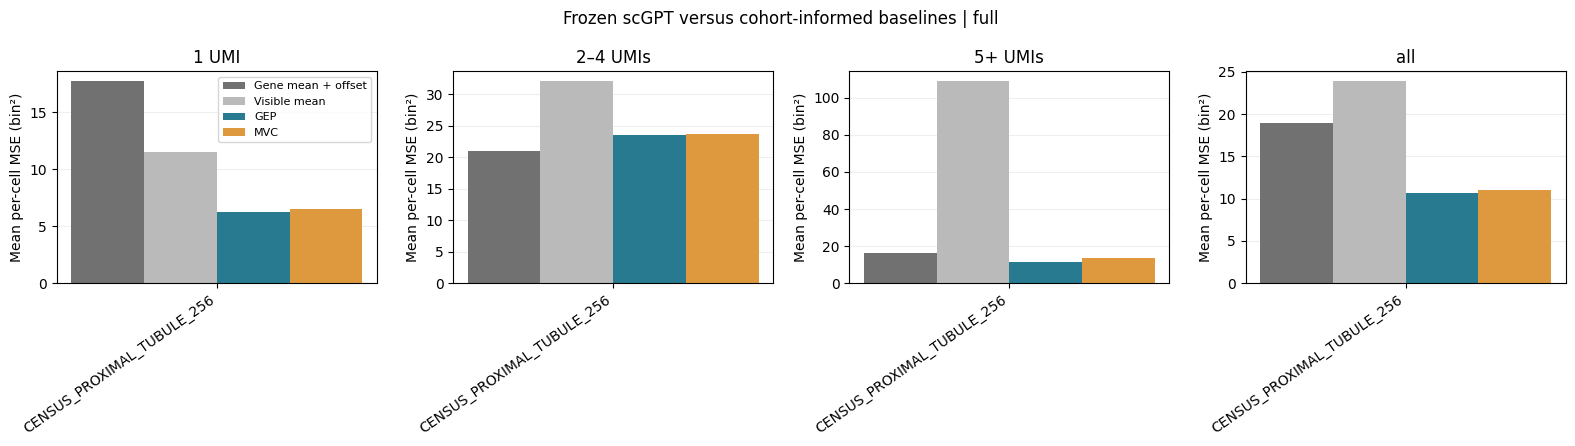

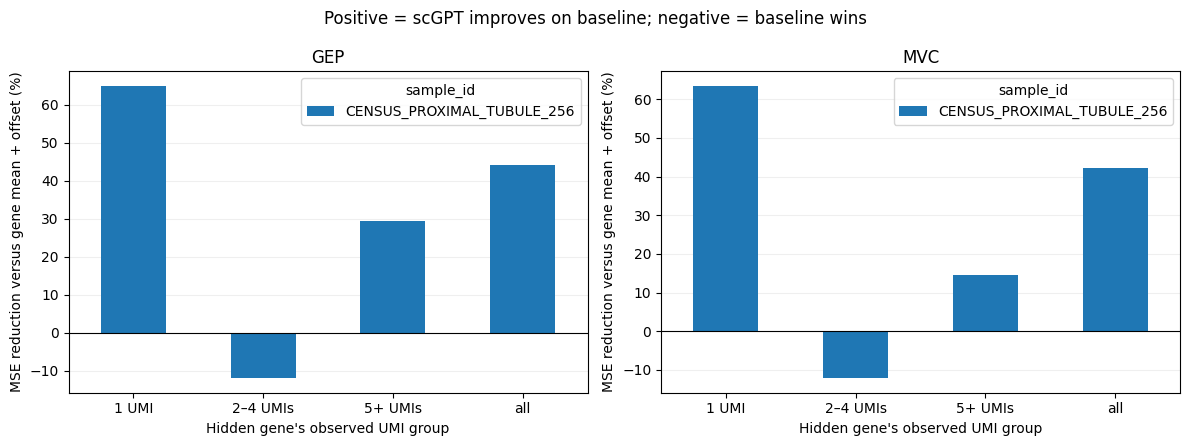

Figures: /home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full/figures


In [12]:
# 8 — Two compact report figures: native-bin loss and advantage over the strong baseline.
import matplotlib.pyplot as plt

figure_dir = RUN_DIR / "figures"
figure_dir.mkdir(exist_ok=True)
sample_order = list(dict.fromkeys(all_summary["sample_id"]))
methods = ["gene_mean_plus_offset", "visible_mean", "GEP", "MVC"]
colors = ["#717171", "#BABABA", "#287A91", "#DE993E"]
labels = ["Gene mean + offset", "Visible mean", "GEP", "MVC"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), squeeze=False)
for ax, group in zip(axes[0], COUNT_GROUPS):
    table = all_summary.loc[all_summary["count_group"].eq(group)].pivot(
        index="sample_id", columns="method", values="mean_MSE").reindex(index=sample_order, columns=methods)
    x = np.arange(len(sample_order))
    width = 0.19
    for k, (method, color, label) in enumerate(zip(methods, colors, labels)):
        ax.bar(x + (k - 1.5) * width, table[method], width, label=label, color=color)
    ax.set_title(group)
    ax.set_xticks(x, sample_order, rotation=35, ha="right")
    ax.set_ylabel("Mean per-cell MSE (bin²)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Frozen scGPT versus cohort-informed baselines | {MODE}")
fig.tight_layout()
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), squeeze=False)
for ax, head in zip(axes[0], ["GEP", "MVC"]):
    table = all_summary.loc[all_summary["method"].eq(head)].pivot(
        index="count_group", columns="sample_id", values="percent_MSE_reduction"
    ).reindex(COUNT_GROUPS)
    table.reindex(columns=sample_order).plot.bar(ax=ax, rot=0)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(head)
    ax.set_xlabel("Hidden gene's observed UMI group")
    ax.set_ylabel("MSE reduction versus gene mean + offset (%)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Positive = scGPT improves on baseline; negative = baseline wins")
fig.tight_layout()
fig.savefig(figure_dir / "relative_gain_by_specimen.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "relative_gain_by_specimen.pdf", bbox_inches="tight")
plt.show()
print("Figures:", figure_dir)


In [13]:
# For realoading in a fresh kernel without rerunning everything:

from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
RESULTS_ROOT = ROOT / "census_expression/results"
RUN_TO_LOAD = None  # Or Path("/home/akash1/scgpt-cna/census_expression/results/..._full")

if RUN_TO_LOAD is None:
    pointer = RESULTS_ROOT / "latest_full_run.json"
    assert pointer.is_file(), (
        "No completed full-run pointer found. Finish summary cell 7, or set RUN_TO_LOAD "
        "to an existing run directory. No inference is launched by this cell."
    )
    RUN_DIR = Path(json.loads(pointer.read_text())["run_dir"])
else:
    RUN_DIR = Path(RUN_TO_LOAD)
assert RUN_DIR.is_dir()
saved_manifest = json.loads((RUN_DIR / "run_manifest.json").read_text())
MODE = saved_manifest["mode"]
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]
all_summary = pd.read_csv(RUN_DIR / "all_specimens_summary.csv")
all_per_cell = pd.read_csv(RUN_DIR / "all_specimens_cell_scores.csv")
profiles = pd.read_csv(RUN_DIR / "measurement_profile_medians.csv")
coverage = pd.read_csv(RUN_DIR / "query_coverage.csv")
print("Loaded saved run:", RUN_DIR)
print("Mode:", MODE, "| masks:", saved_manifest["mask_seeds"])
display(all_summary.loc[all_summary["method"].isin(["gene_mean_plus_offset", "GEP", "MVC"]), [
    "count_group", "method", "n_cells", "mean_MSE", "mean_MAE", "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))
display(profiles.round(3))
print("Run plotting cell 8 if desired. Model weights and raw data were not loaded.")


Loaded saved run: /home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full
Mode: full | masks: [42, 43, 44, 45]


,count_group,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction
0,1 UMI,GEP,128,6.209,1.619,11.505,64.950
2,1 UMI,MVC,128,6.474,1.656,11.240,63.453
5,1 UMI,gene_mean_plus_offset,128,17.714,3.342,0.000,0.000
8,2–4 UMIs,GEP,128,23.574,4.255,-2.518,-11.958
10,2–4 UMIs,MVC,128,23.615,4.254,-2.558,-12.150
13,2–4 UMIs,gene_mean_plus_offset,128,21.056,3.681,0.000,0.000
16,5+ UMIs,GEP,128,11.421,2.359,4.770,29.462
18,5+ UMIs,MVC,128,13.832,2.885,2.360,14.575
21,5+ UMIs,gene_mean_plus_offset,128,16.192,3.214,0.000,0.000
24,all,GEP,128,10.622,2.265,8.372,44.077


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,CENSUS_PROXIMAL_TUBULE_256,not_applicable,Kidney,Census-annotated proximal-tubule reference cohort,1571.5,786.5,786.5,0.697,1.0,7.0,0.697,7.527,256,all_loaded_cells
1,CENSUS_PROXIMAL_TUBULE_256,not_applicable,Kidney,Census-annotated proximal-tubule reference cohort,1575.5,786.5,786.5,0.691,1.0,7.0,0.691,8.045,128,evaluated_cells


Run plotting cell 8 if desired. Model weights and raw data were not loaded.


In [14]:
# 10 — Load Census and kidney results safely. Standalone; no inference or old globals required.
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
from IPython.display import display

comparison_root = Path.home() / "scgpt-cna"
comparison_census_root = comparison_root / "census_expression/results"
comparison_lab_root = comparison_root / "multicase_expression/results"
comparison_census_id = "CENSUS_PROXIMAL_TUBULE_256"
comparison_kidney_ids = ["C3N-00148-01", "C3L-00359-01", "C3L-01287-01"]

# Optional explicit timestamped run directories. Leave as None/{} for automatic recovery.
COMPARISON_CENSUS_RUN = None
COMPARISON_KIDNEY_RUNS = {}   # {"C3N-00148-01": Path("/absolute/timestamped_run_directory")}

if COMPARISON_CENSUS_RUN is None:
    pointer = comparison_census_root / "latest_full_run.json"
    assert pointer.is_file(), "Finish Census summary cell 7, or set COMPARISON_CENSUS_RUN."
    comparison_census_run = Path(json.loads(pointer.read_text())["run_dir"])
else:
    comparison_census_run = Path(COMPARISON_CENSUS_RUN)
comparison_census_manifest = json.loads((comparison_census_run / "run_manifest.json").read_text())
assert comparison_census_manifest["mode"] == "full"
assert comparison_census_manifest["mask_seeds"] == [42, 43, 44, 45]
assert comparison_census_manifest["n_evaluated"] == 128

def comparison_protocol(manifest):
    keys = ["checkpoint_sha256", "helper_sha256", "historical_preprocess_sha256",
            "historical_collator_sha256", "vocab_sha256", "split_seed", "n_reference",
            "n_evaluation_reserved", "n_evaluated", "mask_fraction", "mask_seeds", "config"]
    return json.dumps({key: manifest[key] for key in keys}, sort_keys=True)

def comparison_read_run(run_dir, sid):
    run_dir = Path(run_dir)
    manifest = json.loads((run_dir / "run_manifest.json").read_text())
    assert manifest["mode"] == "full"
    assert comparison_protocol(manifest) == comparison_protocol(comparison_census_manifest), (
        f"Protocol mismatch: {run_dir}. Select a matching run explicitly."
    )
    table = pd.read_csv(run_dir / "all_specimens_summary.csv")
    assert sid in set(table["sample_id"]), f"{sid} is absent from {run_dir}"
    table = table.loc[table["sample_id"].eq(sid)].copy()
    assert not table.duplicated(["sample_id", "count_group", "method"]).any()
    overall = table.loc[table["count_group"].eq("all") & table["method"].isin(["GEP", "MVC"])]
    assert len(overall) == 2 and overall["n_cells"].eq(128).all()
    return table

comparison_census = comparison_read_run(comparison_census_run, comparison_census_id)
comparison_frames = [comparison_census.assign(cohort="Census proximal tubule")]
comparison_sources = [{"cohort": "Census proximal tubule", "sample_id": comparison_census_id,
                       "source_run": str(comparison_census_run)}]

# Never trust the variable name KIDNEY_SUMMARY_FILE alone: it may have been overwritten.
comparison_hint = globals().get("KIDNEY_SUMMARY_FILE")
if comparison_hint is not None and Path(comparison_hint).is_file():
    hint_ids = set(pd.read_csv(comparison_hint, usecols=["sample_id"])["sample_id"])
    if not set(comparison_kidney_ids).issubset(hint_ids):
        print("Ignoring KIDNEY_SUMMARY_FILE: its sample IDs do not identify the three kidney specimens.")

for sid in comparison_kidney_ids:
    if sid in COMPARISON_KIDNEY_RUNS:
        run_dir = Path(COMPARISON_KIDNEY_RUNS[sid])
        table = comparison_read_run(run_dir, sid)
    else:
        candidates = []
        for path in comparison_lab_root.glob("*/all_specimens_summary.csv"):
            try:
                table = comparison_read_run(path.parent, sid)
            except (AssertionError, KeyError, FileNotFoundError):
                continue
            candidates.append((path.parent, table))
        assert candidates, f"No completed protocol-matched kidney run found for {sid}. Set COMPARISON_KIDNEY_RUNS."
        run_dir, table = max(candidates, key=lambda pair: pair[0].name)
    # Verify actual specimen tissue using the saved source manifest.
    specimen_metadata = pd.read_csv(run_dir / "sample_manifest.tsv", sep="\t")
    specimen = specimen_metadata.loc[specimen_metadata["sample_id"].eq(sid)]
    assert len(specimen) == 1 and specimen["primary_site"].iloc[0] == "Kidney"
    comparison_frames.append(table.assign(cohort=sid))
    comparison_sources.append({"cohort": sid, "sample_id": sid, "source_run": str(run_dir)})

census_kidney_comparison = pd.concat(comparison_frames, ignore_index=True)
comparison_source_table = pd.DataFrame(comparison_sources)
assert not census_kidney_comparison.duplicated(["sample_id", "count_group", "method"]).any()
COMPARE_DIR = comparison_root / "census_expression/comparisons" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
COMPARE_DIR.mkdir(parents=True, exist_ok=False)
census_kidney_comparison.to_csv(COMPARE_DIR / "census_vs_kidney_summary.csv", index=False)
comparison_source_table.to_csv(COMPARE_DIR / "source_runs.csv", index=False)
display(comparison_source_table)
display(census_kidney_comparison.loc[
    census_kidney_comparison["method"].isin(["GEP", "MVC"]),
    ["cohort", "count_group", "method", "n_cells", "mean_MSE", "mean_MSE_gain", "percent_MSE_reduction"]
].round(3))
print("Comparison outputs:", COMPARE_DIR)


,cohort,sample_id,source_run
0,Census proximal tubule,CENSUS_PROXIMAL_TUBULE_256,/home/akash1/scgpt-cna/census_expression/resul...
1,C3N-00148-01,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/re...
2,C3L-00359-01,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/re...
3,C3L-01287-01,C3L-01287-01,/home/akash1/scgpt-cna/multicase_expression/re...


,cohort,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,Census proximal tubule,1 UMI,GEP,128,6.209,11.505,64.950
2,Census proximal tubule,1 UMI,MVC,128,6.474,11.240,63.453
8,Census proximal tubule,2–4 UMIs,GEP,128,23.574,-2.518,-11.958
10,Census proximal tubule,2–4 UMIs,MVC,128,23.615,-2.558,-12.150
16,Census proximal tubule,5+ UMIs,GEP,128,11.421,4.770,29.462
18,Census proximal tubule,5+ UMIs,MVC,128,13.832,2.360,14.575
24,Census proximal tubule,all,GEP,128,10.622,8.372,44.077
26,Census proximal tubule,all,MVC,128,10.970,8.024,42.246
32,C3N-00148-01,1 UMI,GEP,128,7.266,2.277,23.863
34,C3N-00148-01,1 UMI,MVC,128,6.819,2.724,28.544


Comparison outputs: /home/akash1/scgpt-cna/census_expression/comparisons/20261110T172638571724Z


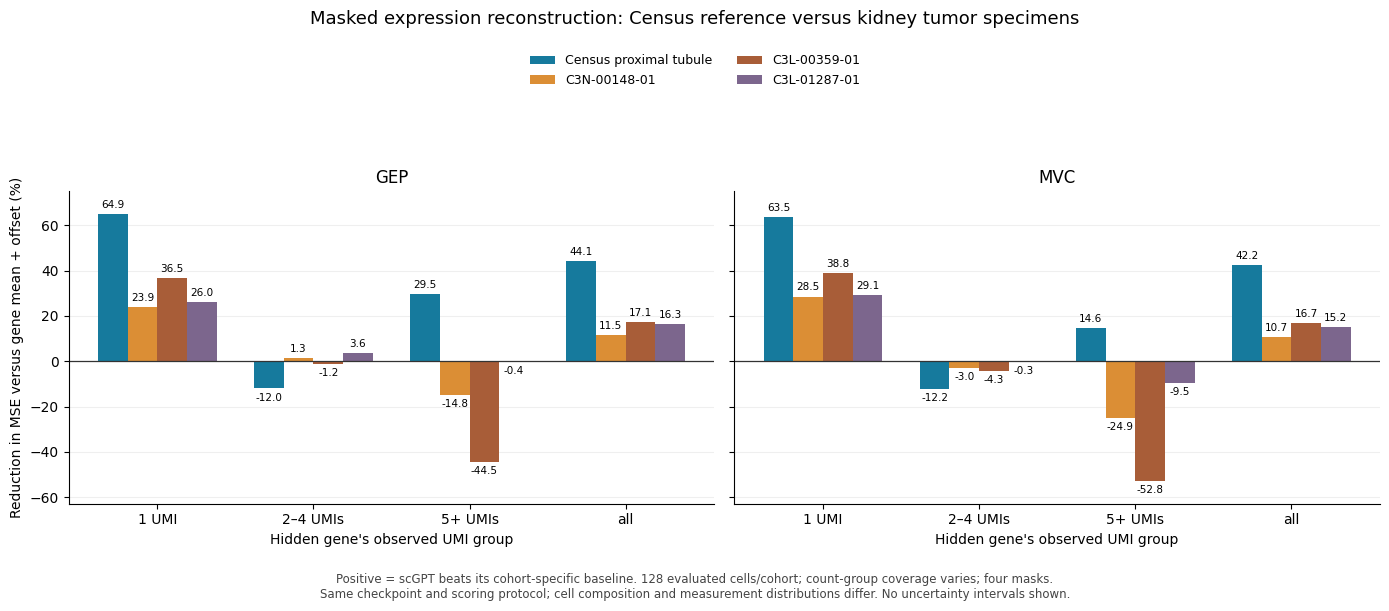

Saved comparison figure and CSVs: /home/akash1/scgpt-cna/census_expression/comparisons/20261110T172638571724Z


In [15]:
# 11 — Compare improvement over the SAME TYPE of baseline, separately by cohort.
import matplotlib.pyplot as plt

comparison_groups = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]
comparison_cohorts = ["Census proximal tubule", *comparison_kidney_ids]
comparison_colors = ["#167A9D", "#DB8E35", "#A85D38", "#7C668D"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
comparison_values = []
for ax, head in zip(axes, ["GEP", "MVC"]):
    table = census_kidney_comparison.loc[census_kidney_comparison["method"].eq(head)].pivot(
        index="count_group", columns="cohort", values="percent_MSE_reduction"
    ).reindex(index=comparison_groups, columns=comparison_cohorts)
    assert table.notna().all().all(), "Incomplete cohort/count-group comparison."
    comparison_values.extend(table.to_numpy().ravel())
    x = np.arange(len(comparison_groups))
    width = .19
    for j, (cohort, color) in enumerate(zip(comparison_cohorts, comparison_colors)):
        bars = ax.bar(x + (j-1.5)*width, table[cohort], width, label=cohort, color=color)
        for bar in bars:
            y = bar.get_height()
            ax.annotate(f"{y:.1f}", (bar.get_x()+bar.get_width()/2, y),
                        xytext=(0, 3 if y >= 0 else -3), textcoords="offset points",
                        ha="center", va="bottom" if y >= 0 else "top", fontsize=7.5)
    ax.axhline(0, color="#333333", linewidth=.9)
    ax.set_xticks(x, comparison_groups)
    ax.set_xlabel("Hidden gene's observed UMI group")
    ax.set_title(head, fontsize=12)
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Reduction in MSE versus gene mean + offset (%)")
axes[0].set_ylim(min(comparison_values)-10, max(comparison_values)+10)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, .94), ncol=2, frameon=False, fontsize=9)
fig.suptitle("Masked expression reconstruction: Census reference versus kidney tumor specimens", y=.995, fontsize=13)
fig.text(.5, .015,
         "Positive = scGPT beats its cohort-specific baseline. 128 evaluated cells/cohort; count-group coverage varies; four masks.\n"
         "Same checkpoint and scoring protocol; cell composition and measurement distributions differ. No uncertainty intervals shown.",
         ha="center", fontsize=8.5, color="#444444")
fig.tight_layout(rect=[0, .075, 1, .81])
fig.savefig(COMPARE_DIR / "census_vs_kidney_mse_reduction.png", dpi=220, bbox_inches="tight")
fig.savefig(COMPARE_DIR / "census_vs_kidney_mse_reduction.pdf", bbox_inches="tight")
plt.show()
print("Saved comparison figure and CSVs:", COMPARE_DIR)
